#

The notebook reproduces the analyses and figures of the study for 32 Neotropical tropical dry forest (TDF) ecoregions (RESOLVE Ecoregions 2017, Tropical and Subtropical Dry Broadleaf Forests biome):

| Section | Index | Period | Outputs |
| --- | --- | --- | --- |
| 3 | SPEI-1, -3, -12, -24 (SPEIbase v2.11) | Jan 1950 – Dec 2024 | Drought months, TFPW Mann–Kendall trends, SPEI-12 heatmap with EM-DAT events (Fig. 4), decadal KDEs (Fig. 5) |
| 4 | SVI from MODIS MOD13A3 EVI | Feb 2000 – Dec 2025 | Vegetation stress months, SVI heatmap (Fig. 6) |
| 5 | SSI-1 from SMAP SPL3SMP_E (v5 + v6) | Apr 2015 – Dec 2025 | Soil moisture drought months, SSI heatmap (Fig. 7) |
| 6 | SPEI-1, SSI-1, SVI | Apr 2015 – Dec 2024 | Spearman coupling (Fig. 8), optimal lags with block-bootstrap CIs (Table 3), lag-correlation curves |

**Requirements.** A Google Earth Engine account with a Cloud project, and the study ecoregions as an Earth Engine asset (see the repository README). The notebook was developed in Google Colab.

**How to run.** Set `GEE_PROJECT` and `ECOREGIONS_ASSET` in the configuration cell, then run all cells in order. Cells tagged `gee` query Earth Engine; extraction takes roughly 30–60 minutes in total. Figures and result tables are written to `outputs/`.

In [ ]:
# Install packages not preinstalled in Google Colab
%pip install -q earthengine-api pymannkendall statsmodels

In [ ]:
import os
import time
import warnings

import ee
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import scipy.stats as st
import seaborn as sns
from scipy import stats as sp_stats
from scipy.stats import linregress, spearmanr
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings('ignore')

try:
    display  # available in Jupyter and Colab
except NameError:
    display = print

## 1. Configuration

All user settings, the ecoregion order used in every figure, the short figure labels (Supplementary Table S1) and the EM-DAT drought events are defined here.

In [ ]:
# --- Earth Engine -----------------------------------------------------------
GEE_PROJECT = 'ee-ID'                 # Earth Engine Cloud project ID
ECOREGIONS_ASSET = 'projects/ee-ID/assets/NEOTDFs'  # study ecoregion polygons based on Dinerstein et al., 2017

# --- Outputs and reproducibility --------------------------------------------
OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_SEED = 42

# --- Analysis periods ---------------------------------------------------------
SPEI_START, SPEI_END = '1950', '2025'          # Jan 1950 - Dec 2024
EVI_START_YEAR, EVI_END_YEAR = 2000, 2025      # MOD13A3 record: Feb 2000 - Dec 2025

# --- Statistical settings -----------------------------------------------------
N_BOOT_KDE = 100
N_BOOT_CI = 5000
N_BOOT_CURVES = 1000
MAX_LAG = 6
FDR_ALPHA = 0.05

# Study ecoregions, in order from north to south; Caribbean islands last
ECOREGION_ORDER = [
    'Sonoran-Sinaloan subtropical dry forest', 'Sinaloan dry forests', 'Sierra de la Laguna dry forests',
    'Bajío dry forests', 'Jalisco dry forests', 'Balsas dry forests', 'Yucatán dry forests',
    'Veracruz dry forests', 'Southern Pacific dry forests', 'Chiapas Depression dry forests',
    'Central American dry forests', 'Panamanian dry forests', 'Cauca Valley dry forests',
    'Sinú Valley dry forests', 'Maracaibo dry forests', 'Lara-Falcón dry forests',
    'Apure-Villavicencio dry forests', 'Magdalena Valley dry forests', 'Patía valley dry forests',
    'Ecuadorian dry forests', 'Tumbes-Piura dry forests', 'Maranhão Babaçu forests',
    'Caatinga', 'Brazilian Atlantic dry forests', 'Chiquitano dry forests',
    'Bolivian montane dry forests', 'Cuban dry forests', 'Hispaniolan dry forests',
    'Jamaican dry forests', 'Puerto Rican dry forests', 'Lesser Antillean dry forests',
    'Trinidad and Tobago dry forest',
]
STUDY_ECOREGIONS = set(ECOREGION_ORDER)

# Numbered short labels used in figures (Supplementary Table S1)
_short = [
    'Sonoran-Sinaloan', 'Sinaloan', 'Sierra de la Laguna', 'Bajío', 'Jalisco', 'Balsas', 'Yucatán',
    'Veracruz', 'Southern Pacific', 'Chiapas Depression', 'Central American', 'Panamanian',
    'Cauca Valley', 'Sinú Valley', 'Maracaibo', 'Lara-Falcón', 'Apure-Villavicencio',
    'Magdalena Valley', 'Patía Valley', 'Ecuadorian', 'Tumbes-Piura', 'Maranhão Babaçu',
    'Caatinga', 'Brazilian Atlantic', 'Chiquitano', 'Bolivian montane', 'Cuban', 'Hispaniolan',
    'Jamaican', 'Puerto Rican', 'Lesser Antillean', 'Trinidad and Tobago',
]
SHORT_LABELS = {name: f'{i} {lab}' for i, (name, lab) in enumerate(zip(ECOREGION_ORDER, _short), start=1)}

# Last continental ecoregion: a dashed line separates the Caribbean islands in the figures
LAST_CONTINENTAL = 'Bolivian montane dry forests'
CARIBBEAN_SPLIT = ECOREGION_ORDER.index(LAST_CONTINENTAL) + 1

# Island ecoregions with no valid SMAP retrievals (land-ocean mask); excluded from the SSI analyses
SMAP_EXCLUDED_NAMES = {
    'Lesser Antillean dry forests', 'Jamaican dry forests',
    'Puerto Rican dry forests', 'Trinidad and Tobago dry forest',
}

# Severity classes and colours shared by the SPEI, SVI and SSI figures
INDEX_BOUNDS = [-99, -2.0, -1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5, 2.0, 99]
INDEX_COLORS = [
    '#67001f',  # extreme drought (<= -2.0)
    '#b2182b',  # severe drought
    '#d6604d',  # moderate drought
    '#f4a582',  # mild drought
    '#F9E7DB',  # near normal (dry side)
    '#E2EDF3',  # near normal (wet side)
    '#A7D0E4',  # mildly wet
    '#549EC9',  # moderately wet
    '#256BB0',  # very wet
    '#053061',  # extremely wet (>= 2.0)
]

# Drought events reported in EM-DAT (Delforge et al., 2025), by ecoregion and year
EMDAT_DROUGHT_EVENTS = {
    'Chiquitano dry forests': [1988, 2014],
    'Lesser Antillean dry forests': [1983, 2010, 2024],
    'Central American dry forests': [1965, 1994, 1997, 1998, 2000, 2001, 2002, 2004, 2009, 2010, 2011, 2012, 2014, 2015, 2016, 2018, 2019, 2023],
    'Ecuadorian dry forests': [1997, 2009, 2010, 2013],
    'Hispaniolan dry forests': [1968, 1974, 1977, 1980, 1981, 1982, 1983, 1992, 1993, 2003, 2004, 2014, 2015, 2016, 2017],
    'Jamaican dry forests': [1968, 2000, 2014],
    'Apure-Villavicencio dry forests': [2024],
    'Magdalena Valley dry forests': [2015, 2016, 2024],
    'Cauca Valley dry forests': [2015, 2016],
    'Patía valley dry forests': [2015, 2016],
    'Sinú Valley dry forests': [2015, 2016],
    'Puerto Rican dry forests': [1994],
    'Sinaloan dry forests': [1988, 1999, 2002],
    'Sonoran-Sinaloan subtropical dry forest': [1988, 1999, 2002],
    'Sierra de la Laguna dry forests': [2002],
    'Veracruz dry forests': [2002],
    'Trinidad and Tobago dry forest': [2010],
    'Bolivian montane dry forests': [1990, 1994, 2000, 2004, 2005, 2008, 2009, 2010, 2013, 2016, 2023, 2024],
    'Cuban dry forests': [1998, 2000, 2004, 2015],
    'Panamanian dry forests': [1983, 2013, 2015],
    'Tumbes-Piura dry forests': [2006],
    'Brazilian Atlantic dry forests': [1970, 1977, 1979, 1987, 1988, 1998, 1999, 2001, 2002, 2005, 2007, 2012, 2013, 2014, 2015, 2016],
}


def out_path(filename):
    """Path of an output file inside OUTPUT_DIR."""
    return os.path.join(OUTPUT_DIR, filename)


def save_table(df, filename, index=False):
    """Write a result table to OUTPUT_DIR as CSV (UTF-8)."""
    df.to_csv(out_path(filename), index=index, encoding='utf-8')
    print(f'  -> saved {out_path(filename)}')

## 2. Earth Engine and study ecoregions

The asset holds 33 RESOLVE 2017 ecoregion polygons. Islas Revillagigedo dry forests is not one of the 32 study ecoregions (it has no valid SPEI data at 0.5°) and is skipped throughout.

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = GEE_PROJECT,
    opt_url='https://earthengine-highvolume.googleapis.com'
)

# Study ecoregion polygons (Earth Engine asset)
geometry = ee.FeatureCollection(ECOREGIONS_ASSET)
n_features = geometry.size().getInfo()
feature_list = geometry.toList(n_features)

# Asset index -> ecoregion name (RESOLVE ECO_NAME); used by every section
feature_names = {}
for i in range(n_features):
    props = ee.Feature(feature_list.get(i)).toDictionary().getInfo()
    feature_names[i] = props.get('ECO_NAME', f'Unknown_ECO_{i}')

not_in_study = sorted(set(feature_names.values()) - STUDY_ECOREGIONS)
missing = sorted(STUDY_ECOREGIONS - set(feature_names.values()))
print(f'Features in asset: {n_features}')
print(f'Skipped (not study ecoregions): {not_in_study}')
assert not missing, f'Study ecoregions missing from the asset: {missing}'

Features in asset: 33
Skipped (not study ecoregions): ['Islas Revillagigedo dry forests']


## 3. Atmospheric drought (SPEI)

In [ ]:
# Load SPEI data
spei = ee.ImageCollection("CSIC/SPEI/2_11") \
    .select('SPEI_01_month', 'SPEI_03_month', 'SPEI_12_month', 'SPEI_24_month') \
    .filterDate(SPEI_START, SPEI_END)

print(f"Total images: {spei.size().getInfo()}")

Total images: 900


In [ ]:
def calculate_spei_stats(image_collection, geometry_feature):
    """Calculate SPEI statistics for a given geometry"""

    def add_spei_property(img):
        stats_dict = img.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry_feature,
            scale=55660,
            maxPixels=1e13,
            bestEffort=True
        )

        img = img.set('spei_01', stats_dict.get('SPEI_01_month'))
        img = img.set('spei_03', stats_dict.get('SPEI_03_month'))
        img = img.set('spei_12', stats_dict.get('SPEI_12_month'))
        img = img.set('spei_24', stats_dict.get('SPEI_24_month'))

        return img

    spei_with_stats = image_collection.map(add_spei_property)

    return spei_with_stats


def get_timeseries_dataframe(image_collection):
    """Extract time series data from image collection and convert to DataFrame"""

    def extract_properties(img):
        date = img.date().format('YYYY-MM-dd')
        spei_01_val = img.get('spei_01')
        spei_03_val = img.get('spei_03')
        spei_12_val = img.get('spei_12')
        spei_24_val = img.get('spei_24')

        return ee.Feature(None, {
            'date': date,
            'timestamp': img.date().millis(),
            'spei_01': spei_01_val,
            'spei_03': spei_03_val,
            'spei_12': spei_12_val,
            'spei_24': spei_24_val
        })

    features = image_collection.map(extract_properties)

    fc_dict = features.getInfo()

    data = []
    for feature in fc_dict['features']:
        data.append(feature['properties'])

    return pd.DataFrame(data)

In [ ]:
def classify_drought(spei_value):
    """Classify drought severity based on SPEI value (6 Categories)"""
    if pd.isna(spei_value):
        return np.nan, np.nan
    if spei_value <= -2.0:
        return 'Extremely Dry', 1
    elif -2.0 < spei_value <= -1.5:
        return 'Severely Dry', 2
    elif -1.5 < spei_value <= -1.0:
        return 'Moderately Dry', 3
    elif -1.0 < spei_value <= -0.5:
        return 'Mild Dry', 4
    elif -0.5 < spei_value <= 0.5:
        return 'Near Normal', 5
    else:
        return 'No Drought', 6

In [ ]:
def summarize_spei_feature(ts_df, feature_index, feature_name):
    """Classify drought severity and compute summary statistics for one ecoregion."""
    ts_df['date'] = pd.to_datetime(ts_df['date'])
    ts_df['year'] = ts_df['date'].dt.year
    ts_df['month'] = ts_df['date'].dt.month

    spei_bands_for_classification = ['spei_01', 'spei_03', 'spei_12', 'spei_24']
    for band in spei_bands_for_classification:
        ts_df[f'drought_class_{band}'], ts_df[f'class_value_{band}'] = zip(*ts_df[band].apply(classify_drought))

    stats = {
        'feature_id': feature_index,
        'feature_name': feature_name,
        'eco_name': feature_name,

        'mean_spei_01': ts_df['spei_01'].mean(),
        'min_spei_01': ts_df['spei_01'].min(),
        'max_spei_01': ts_df['spei_01'].max(),
        'median_spei_01': ts_df['spei_01'].median(),
        'std_dev_spei_01': ts_df['spei_01'].std(),

        'mean_spei_03': ts_df['spei_03'].mean(),
        'min_spei_03': ts_df['spei_03'].min(),
        'max_spei_03': ts_df['spei_03'].max(),
        'median_spei_03': ts_df['spei_03'].median(),
        'std_dev_spei_03': ts_df['spei_03'].std(),

        'mean_spei_12': ts_df['spei_12'].mean(),
        'min_spei_12': ts_df['spei_12'].min(),
        'max_spei_12': ts_df['spei_12'].max(),
        'median_spei_12': ts_df['spei_12'].median(),
        'std_dev_spei_12': ts_df['spei_12'].std(),

        'mean_spei_24': ts_df['spei_24'].mean(),
        'min_spei_24': ts_df['spei_24'].min(),
        'max_spei_24': ts_df['spei_24'].max(),
        'median_spei_24': ts_df['spei_24'].median(),
        'std_dev_spei_24': ts_df['spei_24'].std(),

        # Drought class counts for each SPEI band
        'extreme_drought_count_01': (ts_df['drought_class_spei_01'] == 'Extremely Dry').sum(),
        'severe_drought_count_01': (ts_df['drought_class_spei_01'] == 'Severely Dry').sum(),
        'moderate_drought_count_01': (ts_df['drought_class_spei_01'] == 'Moderately Dry').sum(),
        'mild_drought_count_01': (ts_df['drought_class_spei_01'] == 'Mild Dry').sum(),
        'normal_count_01': (ts_df['drought_class_spei_01'] == 'Near Normal').sum(),
        'no_drought_count_01': (ts_df['drought_class_spei_01'] == 'No Drought').sum(),

        'extreme_drought_count_03': (ts_df['drought_class_spei_03'] == 'Extremely Dry').sum(),
        'severe_drought_count_03': (ts_df['drought_class_spei_03'] == 'Severely Dry').sum(),
        'moderate_drought_count_03': (ts_df['drought_class_spei_03'] == 'Moderately Dry').sum(),
        'mild_drought_count_03': (ts_df['drought_class_spei_03'] == 'Mild Dry').sum(),
        'normal_count_03': (ts_df['drought_class_spei_03'] == 'Near Normal').sum(),
        'no_drought_count_03': (ts_df['drought_class_spei_03'] == 'No Drought').sum(),

        'extreme_drought_count_12': (ts_df['drought_class_spei_12'] == 'Extremely Dry').sum(),
        'severe_drought_count_12': (ts_df['drought_class_spei_12'] == 'Severely Dry').sum(),
        'moderate_drought_count_12': (ts_df['drought_class_spei_12'] == 'Moderately Dry').sum(),
        'mild_drought_count_12': (ts_df['drought_class_spei_12'] == 'Mild Dry').sum(),
        'normal_count_12': (ts_df['drought_class_spei_12'] == 'Near Normal').sum(),
        'no_drought_count_12': (ts_df['drought_class_spei_12'] == 'No Drought').sum(),

        'extreme_drought_count_24': (ts_df['drought_class_spei_24'] == 'Extremely Dry').sum(),
        'severe_drought_count_24': (ts_df['drought_class_spei_24'] == 'Severely Dry').sum(),
        'moderate_drought_count_24': (ts_df['drought_class_spei_24'] == 'Moderately Dry').sum(),
        'mild_drought_count_24': (ts_df['drought_class_spei_24'] == 'Mild Dry').sum(),
        'normal_count_24': (ts_df['drought_class_spei_24'] == 'Near Normal').sum(),
        'no_drought_count_24': (ts_df['drought_class_spei_24'] == 'No Drought').sum(),

        'total_observations': len(ts_df)
    }

    return stats, ts_df

In [ ]:
def extract_spei_feature(feature_index):
    """Extract the monthly ecoregion-mean SPEI time series for one feature (Earth Engine)."""
    feature = ee.Feature(feature_list.get(feature_index))
    spei_feature = calculate_spei_stats(spei, feature.geometry())
    return get_timeseries_dataframe(spei_feature)


feature_stats_list = []
feature_timeseries_dict = {}

for i in range(n_features):
    feature_name = feature_names[i]
    if feature_name not in STUDY_ECOREGIONS:
        print(f"  - Skipping {feature_name}: not a study ecoregion.")
        continue
    print(f"Processing feature {i+1}/{n_features}: {feature_name}")
    try:
        raw_ts = extract_spei_feature(i)
        stats, ts_df = summarize_spei_feature(raw_ts, i, feature_name)

        if ts_df['spei_01'].notna().sum() == 0:
            print(f"  ⚠ Skipping {feature_name} (Feature {i}): no valid SPEI observations.")
            continue

        feature_stats_list.append(stats)
        feature_timeseries_dict[i] = ts_df
        print(f"  ✓ Completed: {feature_name}")
    except Exception as e:
        print(f"  ✗ Error processing feature {i}: {e}")

  - Skipping Islas Revillagigedo dry forests: not a study ecoregion.
Processing feature 2/33: Chiquitano dry forests
  ✓ Completed: Chiquitano dry forests
Processing feature 3/33: Lara-Falcón dry forests
  ✓ Completed: Lara-Falcón dry forests
Processing feature 4/33: Maranhão Babaçu forests
  ✓ Completed: Maranhão Babaçu forests
Processing feature 5/33: Yucatán dry forests
  ✓ Completed: Yucatán dry forests
Processing feature 6/33: Lesser Antillean dry forests
  ✓ Completed: Lesser Antillean dry forests
Processing feature 7/33: Apure-Villavicencio dry forests
  ✓ Completed: Apure-Villavicencio dry forests
Processing feature 8/33: Central American dry forests
  ✓ Completed: Central American dry forests
Processing feature 9/33: Ecuadorian dry forests
  ✓ Completed: Ecuadorian dry forests
Processing feature 10/33: Hispaniolan dry forests
  ✓ Completed: Hispaniolan dry forests
Processing feature 11/33: Jalisco dry forests
  ✓ Completed: Jalisco dry forests
Processing feature 12/33: Jamaica

In [ ]:
# Create DataFrame with statistics
df_feature_stats = pd.DataFrame(feature_stats_list)
df_feature_stats = df_feature_stats.dropna(subset=['mean_spei_01'])

print("\n\nFeature Statistics Summary:")
print(df_feature_stats)
save_table(df_feature_stats, 'spei_summary_statistics.csv')

all_timeseries_list_with_id = []
for fid, df in feature_timeseries_dict.items():
    temp_df = df.copy()
    temp_df['feature_id'] = fid
    all_timeseries_list_with_id.append(temp_df)

all_timeseries_df = pd.concat(all_timeseries_list_with_id, ignore_index=True)

all_timeseries_df['date'] = pd.to_datetime(all_timeseries_df['date'])
all_timeseries_df['year'] = all_timeseries_df['date'].dt.year
all_timeseries_df['month'] = all_timeseries_df['date'].dt.month
all_timeseries_df['decade_factor'] = (all_timeseries_df['year'] // 10) * 10



Feature Statistics Summary:
    feature_id                             feature_name  \
0            1                   Chiquitano dry forests   
1            2                  Lara-Falcón dry forests   
2            3                  Maranhão Babaçu forests   
3            4                      Yucatán dry forests   
4            5             Lesser Antillean dry forests   
5            6          Apure-Villavicencio dry forests   
6            7             Central American dry forests   
7            8                   Ecuadorian dry forests   
8            9                  Hispaniolan dry forests   
9           10                      Jalisco dry forests   
10          11                     Jamaican dry forests   
11          12             Magdalena Valley dry forests   
12          13                    Maracaibo dry forests   
13          14                 Puerto Rican dry forests   
14          15          Sierra de la Laguna dry forests   
15          16            

### 3.1 Long-term trends (TFPW Mann–Kendall)

Trend-free pre-whitening Mann–Kendall test (Yue & Wang, 2002) with Sen's slope converted to change per decade (× 120). Benjamini–Hochberg FDR correction is applied across all ecoregions and timescales together.

In [ ]:
#Mann-Kendall analysis with Trend-Free Pre-whitening (TFPW)

print("Starting Mann-Kendall analysis with Trend-Free Pre-whitening (TFPW)... ")

spei_scales = ['spei_01', 'spei_03', 'spei_12', 'spei_24']
mk_tfpw_results = []

for fid, df_ts in feature_timeseries_dict.items():
    f_name = feature_names.get(fid, f"Unknown_{fid}")

    for scale in spei_scales:
        if scale not in df_ts.columns:
            continue

        data_series = df_ts[scale].dropna().values

        if len(data_series) < 30:
            continue

        try:
            res = mk.trend_free_pre_whitening_modification_test(data_series)

            # Monthly slope to Decadal slope
            decadal_slope = res.slope * 120
            direction = 'Drying' if res.slope < 0 else 'Wetting' if res.slope > 0 else 'No Trend'

            mk_tfpw_results.append({
                'feature_id': fid,
                'feature_name': f_name,
                'timescale': scale,
                'slope_monthly': res.slope,
                'slope_decadal': decadal_slope,
                'trend_direction': direction,
                'p_value': res.p,
                'mk_trend_type': res.trend
            })
        except Exception as e:
            print(f"  ! Error in {f_name} ({scale}): {e}")

df_mk_tfpw = pd.DataFrame(mk_tfpw_results)

# Benjamini-Hochberg (FDR) Correction
if not df_mk_tfpw.empty:
    _, p_adj, _, _ = multipletests(df_mk_tfpw['p_value'], alpha=0.05, method='fdr_bh')
    df_mk_tfpw['p_value_adj'] = p_adj
    df_mk_tfpw['is_significant_fdr'] = df_mk_tfpw['p_value_adj'] < 0.05

    df_mk_tfpw['p_value_formatted'] = df_mk_tfpw['p_value_adj'].apply(lambda x: '< 0.001' if x < 0.001 else f"{x:.4f}")

    print("\u2713 TFPW Mann-Kendall and FDR correction complete.")

    sig_results = df_mk_tfpw[df_mk_tfpw['is_significant_fdr']].sort_values(['timescale', 'slope_decadal'])

    print(f"\nFound {len(sig_results)} statistically significant trends after FDR correction.")
    display(sig_results[['feature_name', 'timescale', 'trend_direction', 'slope_decadal', 'p_value_formatted']])

    # --- Summary count by timescale and direction ---
    summary = (
        sig_results.groupby(['timescale', 'trend_direction'])
        .size()
        .reset_index(name='n_sites')
    )
    print("\nSummary of significant trends by timescale and direction:")
    display(summary)

    # --- Conflicting sites check ---
    print("\nSites with conflicting trend directions across timescales:")
    for ts_dry, ts_wet in [('spei_01', 'spei_24'), ('spei_03', 'spei_24'), ('spei_01', 'spei_12')]:
        drying = set(sig_results[
            (sig_results['trend_direction'] == 'Drying') &
            (sig_results['timescale'] == ts_dry)
        ]['feature_name'])

        wetting = set(sig_results[
            (sig_results['trend_direction'] == 'Wetting') &
            (sig_results['timescale'] == ts_wet)
        ]['feature_name'])

        conflicting = drying.intersection(wetting)
        if conflicting:
            print(f"  Drying at {ts_dry} and wetting at {ts_wet} ({len(conflicting)} sites):")
            for site in sorted(conflicting):
                print(f"    - {site}")
        else:
            print(f"  No conflicting sites between {ts_dry} and {ts_wet}.")


Starting Mann-Kendall analysis with Trend-Free Pre-whitening (TFPW)... 
✓ TFPW Mann-Kendall and FDR correction complete.

Found 105 statistically significant trends after FDR correction.


,feature_name,timescale,trend_direction,slope_decadal,p_value_formatted
124,Brazilian Atlantic dry forests,spei_01,Drying,-0.097170,< 0.001
36,Jalisco dry forests,spei_01,Drying,-0.077256,< 0.001
56,Sierra de la Laguna dry forests,spei_01,Drying,-0.076255,< 0.001
112,Southern Pacific dry forests,spei_01,Drying,-0.075577,< 0.001
60,Sinaloan dry forests,spei_01,Drying,-0.072434,< 0.001
...,...,...,...,...,...
47,Magdalena Valley dry forests,spei_24,Wetting,0.089588,< 0.001
91,Cauca Valley dry forests,spei_24,Wetting,0.094240,< 0.001
15,Yucatán dry forests,spei_24,Wetting,0.111962,< 0.001
67,Sinú Valley dry forests,spei_24,Wetting,0.157579,< 0.001



Summary of significant trends by timescale and direction:


,timescale,trend_direction,n_sites
0,spei_01,Drying,15
1,spei_01,Wetting,3
2,spei_03,Drying,19
3,spei_03,Wetting,6
4,spei_12,Drying,21
5,spei_12,Wetting,9
6,spei_24,Drying,23
7,spei_24,Wetting,9



Sites with conflicting trend directions across timescales:
  No conflicting sites between spei_01 and spei_24.
  Drying at spei_03 and wetting at spei_24 (1 sites):
    - Maranhão Babaçu forests
  No conflicting sites between spei_01 and spei_12.
  -> saved outputs/spei_mann_kendall_tfpw_trends.csv


### 3.2 SPEI-12 heatmap, drought months and EM-DAT events (Figure 4)

In [ ]:
# Annual mean SPEI-12 per ecoregion
annual_mean_spei12_data = []

all_years_set = set()
for df in feature_timeseries_dict.values():
    if 'year' in df.columns:
        all_years_set.update(df['year'].unique())
all_years = sorted(list(all_years_set))

for feature_id, df in feature_timeseries_dict.items():
    feature_name = feature_names.get(feature_id, f'F{feature_id}')

    if 'spei_12' in df.columns:
        yearly_mean_spei12 = df.groupby('year')['spei_12'].mean().reindex(all_years)

        annual_mean_spei12_data.append(pd.Series(yearly_mean_spei12, name=feature_name))
    else:
        print(f"  Warning: 'spei_12' column not found for feature {feature_name}. Skipping.")

if annual_mean_spei12_data:
    df_annual_mean_spei12 = pd.concat(annual_mean_spei12_data, axis=1).T
    df_annual_mean_spei12.columns = all_years
    df_annual_mean_spei12 = df_annual_mean_spei12.dropna(axis=1, how='all')

    print("\n\u2713 Annual mean SPEI-12 calculated for all features successfully.")
    print(f"Shape of df_annual_mean_spei12: {df_annual_mean_spei12.shape}")
    print("First 5 rows of df_annual_mean_spei12:")
    print(df_annual_mean_spei12.head())
else:
    print("\n\u26a0 No SPEI-12 data available to create df_annual_mean_spei12.")


✓ Annual mean SPEI-12 calculated for all features successfully.
Shape of df_annual_mean_spei12: (32, 75)
First 5 rows of df_annual_mean_spei12:
                                  1950      1951      1952      1953  \
Chiquitano dry forests        0.616731  0.640340  0.362767 -0.299755   
Lara-Falcón dry forests       1.603162  1.278489 -0.255428 -0.670839   
Maranhão Babaçu forests       0.586338 -1.154942 -0.247902 -0.965740   
Yucatán dry forests          -0.716012 -0.753008  0.037796  0.967556   
Lesser Antillean dry forests  0.538416  0.830011  0.810759  0.558909   

                                  1954      1955      1956      1957  \
Chiquitano dry forests        1.125514 -0.341804  1.270652  0.950149   
Lara-Falcón dry forests      -1.007317  0.697605  0.929345 -0.675307   
Maranhão Babaçu forests      -0.987581 -0.338592 -0.223835  0.344666   
Yucatán dry forests           0.384665 -0.449418  0.513580  0.911803   
Lesser Antillean dry forests  0.488732  1.118751  1.850726  0.

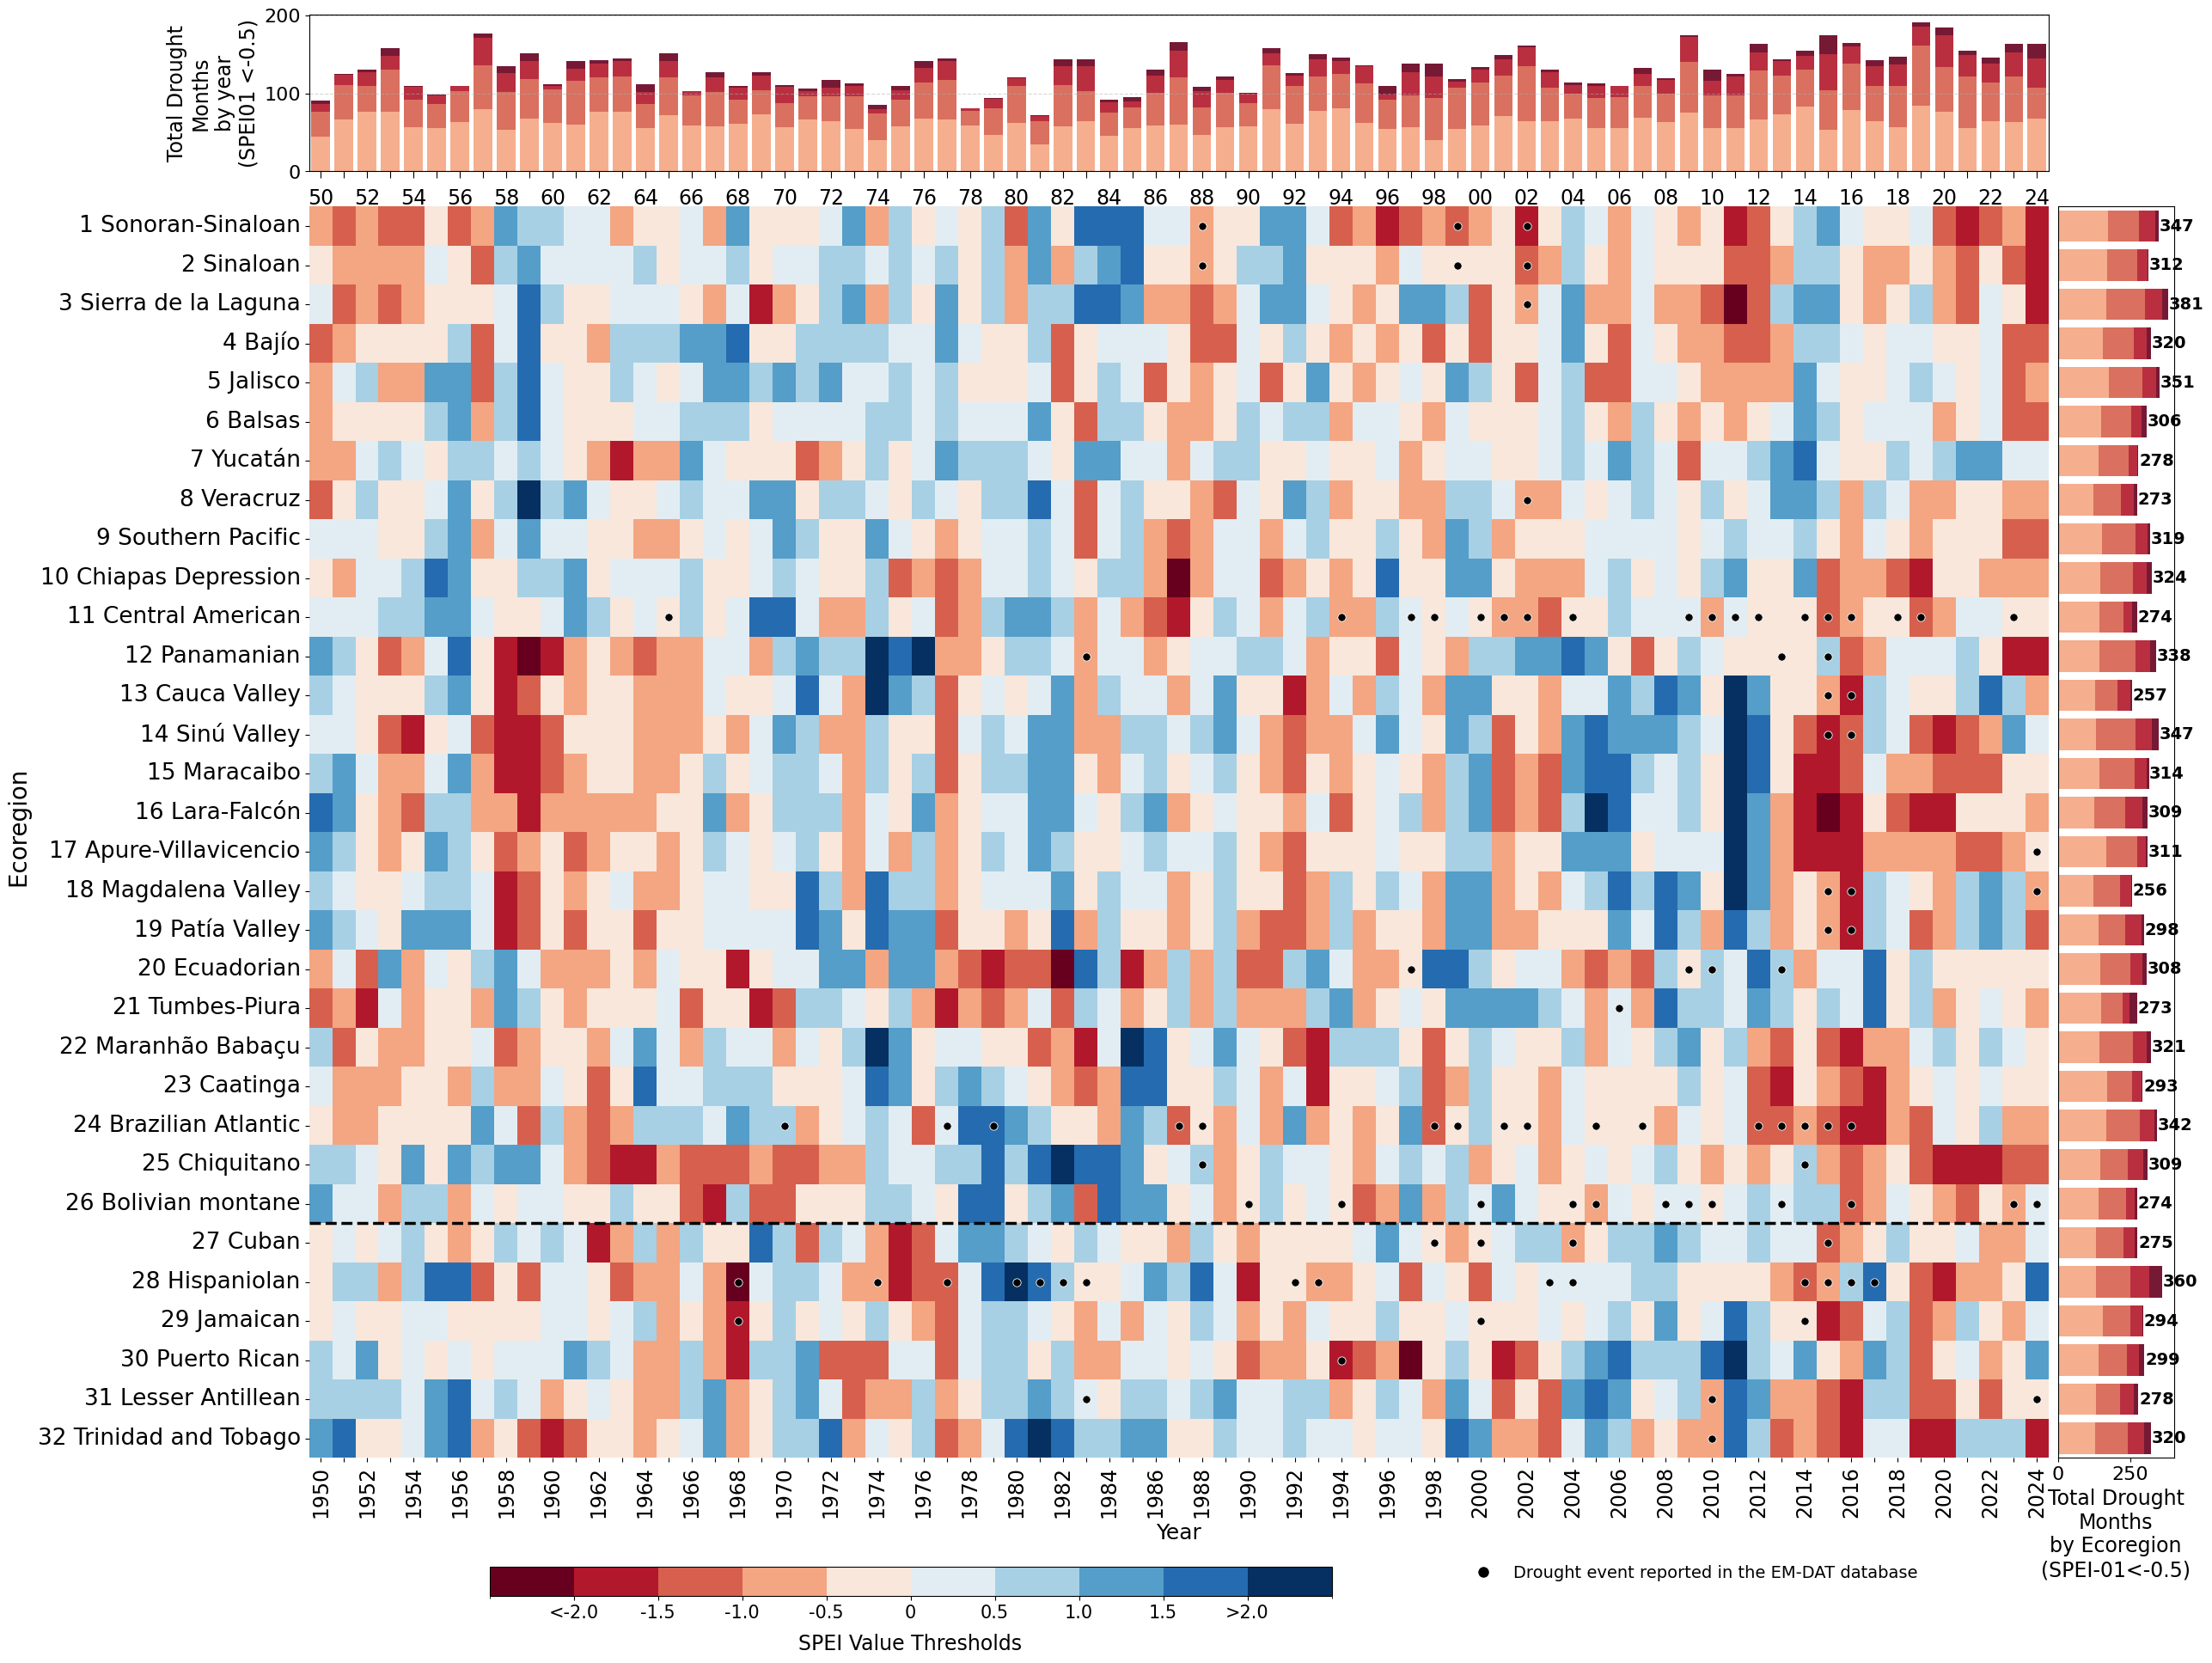

  -> saved outputs/spei1_drought_months_by_year.csv
  -> saved outputs/spei1_drought_months_by_ecoregion.csv


In [ ]:
desired_order = ECOREGION_ORDER
label_mapping = SHORT_LABELS
drought_events = EMDAT_DROUGHT_EVENTS
bounds = INDEX_BOUNDS
colors_list = INDEX_COLORS
cmap_discrete = mcolors.ListedColormap(colors_list)
norm_discrete = mcolors.BoundaryNorm(bounds, cmap_discrete.N)

# Data Preparation
heatmap_data = df_annual_mean_spei12.reindex(desired_order).astype(float)
active_features = heatmap_data.index.tolist()
all_years_int = heatmap_data.columns.astype(int).tolist()
year_to_idx = {year: i for i, year in enumerate(all_years_int)}

drought_classes = ['Extremely Dry', 'Severely Dry', 'Moderately Dry', 'Mild Dry']
drought_bar_colors = colors_list[:4]

df_top_counts = all_timeseries_df[all_timeseries_df['drought_class_spei_01'].isin(drought_classes)].groupby(['year', 'drought_class_spei_01']).size().unstack(fill_value=0)
df_top_counts = df_top_counts.reindex(index=all_years_int, columns=drought_classes, fill_value=0)

all_timeseries_df['feature_name_mapped'] = all_timeseries_df['feature_id'].map(feature_names)
df_right_counts = all_timeseries_df[all_timeseries_df['drought_class_spei_01'].isin(drought_classes)].groupby(['feature_name_mapped', 'drought_class_spei_01']).size().unstack(fill_value=0)
df_right_counts = df_right_counts.reindex(index=active_features, columns=drought_classes, fill_value=0)

# Plotting
fig = plt.figure(figsize=(28, 23))

gs = gridspec.GridSpec(2, 2, width_ratios=[len(all_years_int), 5], height_ratios=[4, len(active_features)], wspace=0.01, hspace=0.05)

ax_top = fig.add_subplot(gs[0, 0])
ax_heatmap = fig.add_subplot(gs[1, 0])
ax_right = fig.add_subplot(gs[1, 1])

bottom_top = np.zeros(len(all_years_int))
for i, d_class in enumerate(reversed(drought_classes)):
    ax_top.bar(np.arange(len(all_years_int)), df_top_counts[d_class], bottom=bottom_top, color=drought_bar_colors[3-i], width=0.8, alpha=0.9)
    bottom_top += df_top_counts[d_class].values

ax_top.set_xlim(-0.5, len(all_years_int) - 0.5)
ax_top.set_ylabel('Total Drought\nMonths\nby year\n(SPEI01 <-0.5)', fontsize=17)
ax_top.tick_params(axis='y', labelsize=16)
ax_top.grid(axis='y', linestyle='--', alpha=0.5)

ax_top.set_xticks(np.arange(len(all_years_int)))
top_x_labels = [str(y)[-2:] if y % 2 == 0 else '' for y in all_years_int]
ax_top.set_xticklabels(top_x_labels, fontsize=17, rotation=0)
ax_top.tick_params(axis='x', labelbottom=True, labeltop=False, bottom=True, length=6, pad=8)

sns.heatmap(heatmap_data, cmap=cmap_discrete, norm=norm_discrete, ax=ax_heatmap, cbar=False)
ax_heatmap.set_ylabel(' Ecoregion', fontsize=20)
ax_heatmap.set_xlabel('Year', fontsize=18)

mapped_y_labels = [label_mapping.get(label.get_text(), label.get_text()) for label in ax_heatmap.get_yticklabels()]
ax_heatmap.set_yticklabels(mapped_y_labels, fontsize=19)

for feature, years in drought_events.items():
    if feature in active_features:
        y_idx = active_features.index(feature)
        for yr in years:
            if yr in year_to_idx:
                ax_heatmap.scatter(year_to_idx[yr] + 0.5, y_idx + 0.5, color='black', s=45, edgecolors='white', linewidths=0.6, zorder=5)

ax_heatmap.set_xticks(np.arange(len(all_years_int)) + 0.5)
ax_heatmap.set_xticklabels([str(y) if y % 2 == 0 else '' for y in all_years_int], fontsize=17, rotation=90)
ax_heatmap.axhline(y=CARIBBEAN_SPLIT, color='black', linewidth=2.5, linestyle='--')

left_right = np.zeros(len(active_features))
for i, d_class in enumerate(reversed(drought_classes)):
    ax_right.barh(np.arange(len(active_features)), df_right_counts[d_class], left=left_right, color=drought_bar_colors[3-i], height=0.8, alpha=0.9)
    left_right += df_right_counts[d_class].values

ax_right.set_ylim(len(active_features) - 0.5, -0.5)
ax_right.set_xlabel('Total Drought\nMonths\nby Ecoregion\n(SPEI-01<-0.5)', fontsize=17)
ax_right.tick_params(axis='x', labelsize=16)
ax_right.tick_params(axis='y', labelleft=False, length=0)
for i, val in enumerate(left_right):
    if val > 0: ax_right.text(val + 2, i, f'{int(val)}', va='center', fontsize=14, fontweight='bold')

cbar_ax = fig.add_axes([0.2, 0.08, 0.35, 0.015])
sm = plt.cm.ScalarMappable(cmap=cmap_discrete, norm=norm_discrete)

cbar_ticks = [-2.0, -1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5, 2.0]
cbar_labels = ['<-2.0', '-1.5', '-1.0', '-0.5', '0', '0.5', '1.0', '1.5', '>2.0']
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
cbar.ax.set_xticklabels(cbar_labels, fontsize=15)
cbar.set_label('SPEI Value Thresholds', fontsize=17, labelpad=10)

emdat_legend_text = 'Drought event reported in the EM-DAT database'
emdat_marker = plt.Line2D([0], [0], marker='o', color='w', label=emdat_legend_text, markerfacecolor='black', markersize=10, markeredgecolor='white')
fig.legend(handles=[emdat_marker], loc='lower center', bbox_to_anchor=(0.7, 0.08), frameon=False, fontsize=14)

plt.subplots_adjust(bottom=0.15)
plt.savefig(out_path('spei_drought_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

### 3.3 Decadal distributional shifts (Figure 5)

Gaussian kernel density estimates of SPEI values pooled across ecoregions, by decade, with 95% confidence bands from an ordinary (i.i.d.) bootstrap of resamples.

Kernel Density Estimate plots for all SPEI timescales across decades...


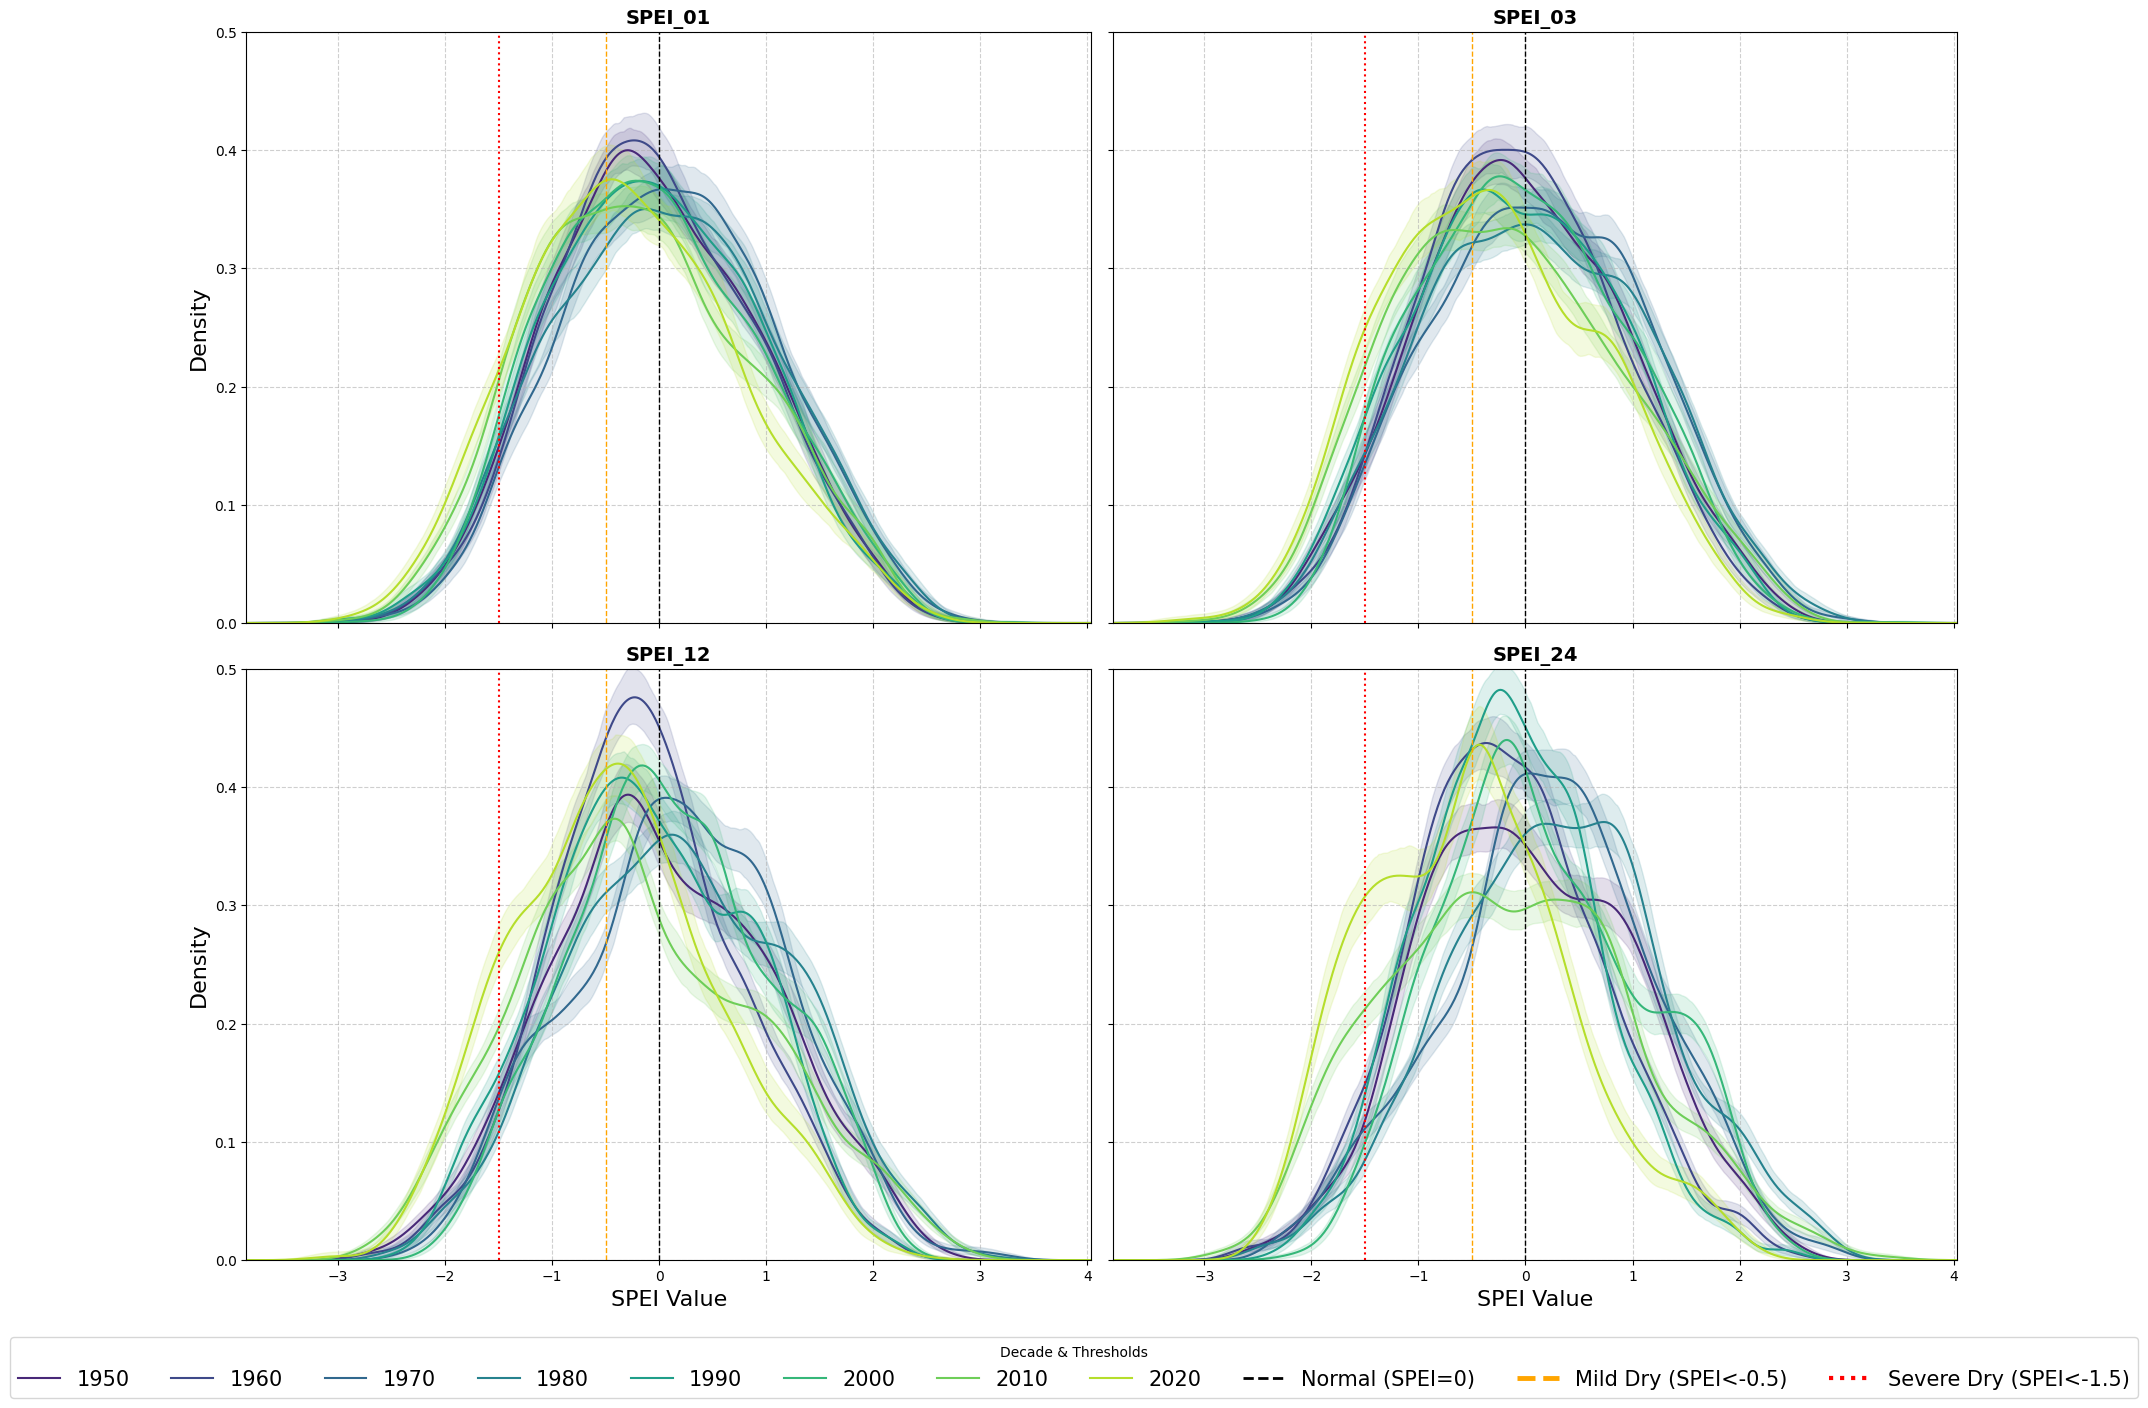

✓ KDE plots for all SPEI timescales across decades saved as 'outputs/kde_all_spei_across_decades_with_ci.png'.


In [ ]:
print("Kernel Density Estimate plots for all SPEI timescales across decades...")


spei_cols_to_plot = ['spei_01', 'spei_03', 'spei_12', 'spei_24']

fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharex=True, sharey=True, constrained_layout=True)
axes = axes.flatten()

kde_legend_handles = []
ref_line_handles = []
legend_added = False

spei_min_val = all_timeseries_df[spei_cols_to_plot].min().min()
spei_max_val = all_timeseries_df[spei_cols_to_plot].max().max()
x_vals_global = np.linspace(spei_min_val - 0.5, spei_max_val + 0.5, 500)

n_bootstrap_samples = N_BOOT_KDE
np.random.seed(RANDOM_SEED)

for i, spei_col in enumerate(spei_cols_to_plot):
    ax = axes[i]

    df_kde_data_current = all_timeseries_df[[spei_col, 'decade_factor']].dropna(subset=[spei_col]).copy()
    df_kde_data_current['decade_factor'] = df_kde_data_current['decade_factor'].astype(str)

    if not df_kde_data_current.empty:
        unique_decades = sorted(df_kde_data_current['decade_factor'].unique())
        palette = sns.color_palette('viridis', n_colors=len(unique_decades))
        decade_color_map = {decade_label: palette[j] for j, decade_label in enumerate(unique_decades)}

        for decade_label in unique_decades:
            decade_data = df_kde_data_current[df_kde_data_current['decade_factor'] == decade_label][spei_col].dropna().values
            if len(decade_data) < 5:
                continue

            bootstrapped_kdes = []
            for _ in range(n_bootstrap_samples):
                sample = np.random.choice(decade_data, size=len(decade_data), replace=True)
                if len(np.unique(sample)) > 1:
                    kde_func = st.gaussian_kde(sample)
                    bootstrapped_kdes.append(kde_func(x_vals_global))

            if bootstrapped_kdes:
                bootstrapped_kdes = np.array(bootstrapped_kdes)
                kde_mean = np.mean(bootstrapped_kdes, axis=0)
                kde_lower = np.percentile(bootstrapped_kdes, 2.5, axis=0)
                kde_upper = np.percentile(bootstrapped_kdes, 97.5, axis=0)

                color = decade_color_map[decade_label]
                ax.plot(x_vals_global, kde_mean, color=color, linewidth=1.5)
                ax.fill_between(x_vals_global, kde_lower, kde_upper, color=color, alpha=0.15)

        ax.axvline(x=0, color='black', linestyle='--', linewidth=1)
        ax.axvline(x=-0.5, color='orange', linestyle='--', linewidth=1)
        ax.axvline(x=-1.5, color='red', linestyle=':', linewidth=1.5)

        ax.set_title(f'{spei_col.upper()}', fontsize=14, fontweight='bold')

        if i >= 2:
            ax.set_xlabel('SPEI Value', fontsize=16)
        if i % 2 == 0:
            ax.set_ylabel('Density', fontsize=16)

        ax.set_ylim(0, 0.5)
        ax.set_xlim(x_vals_global.min(), x_vals_global.max())
        ax.grid(True, linestyle='--', alpha=0.6)

        if not legend_added:
            for decade_label in unique_decades:
                kde_legend_handles.append(plt.Line2D([0], [0], color=decade_color_map[decade_label], lw=1.5, label=decade_label))
            ref_line_handles.append(plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Normal (SPEI=0)'))
            ref_line_handles.append(plt.Line2D([0], [0], color='orange', linestyle='--', linewidth=3.5, label='Mild Dry (SPEI<-0.5)'))
            ref_line_handles.append(plt.Line2D([0], [0], color='red', linestyle=':', linewidth=3, label='Severe Dry (SPEI<-1.5)'))
            legend_added = True
    else:
        ax.text(0.5, 0.5, f'No data for {spei_col.upper()}', ha='center', va='center', fontsize=16, color='gray')
        ax.set_title(f'{spei_col.upper()}', fontsize=18, fontweight='bold')
        if i >= 2:
            ax.set_xlabel('SPEI Value', fontsize=18)
        if i % 2 == 0:
            ax.set_ylabel('Density', fontsize=18)
        ax.set_ylim(0, 0.5)

final_handles_overall = kde_legend_handles + ref_line_handles
final_labels_overall = [h.get_label() for h in final_handles_overall]

fig.legend(handles=final_handles_overall, labels=final_labels_overall,
           title='Decade & Thresholds',
           loc='lower center',
           bbox_to_anchor=(0.5, -0.01),
           fontsize=15, frameon=True, ncol=11)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plot_filename = out_path('kde_all_spei_across_decades_with_ci.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f"✓ KDE plots for all SPEI timescales across decades saved as '{plot_filename}'.")

## 4. Vegetation stress (SVI)

In [ ]:
# Load the full collection to access both EVI and SummaryQA bands

start_year_evi = EVI_START_YEAR
end_year_evi = EVI_END_YEAR
print(f"EVI Analysis Period: {start_year_evi} - {end_year_evi}")

raw_collection = ee.ImageCollection("MODIS/061/MOD13A3") \
    .filterDate(f'{start_year_evi}-01-01', f'{end_year_evi}-12-31')

def preprocess_evi(image):
    evi = image.select('EVI').multiply(0.0001)

    valid_range_mask = evi.gte(-0.2).And(evi.lte(1.0))

    qa = image.select('SummaryQA')
    quality_mask = qa.lte(1)

    evi_masked = evi \
        .updateMask(valid_range_mask) \
        .updateMask(quality_mask)

    return image.addBands(evi_masked, overwrite=True) \
                .select('EVI') \
                .copyProperties(image, ['system:time_start', 'system:time_end'])

evi_collection = raw_collection.map(preprocess_evi)

print(f"Total images in EVI collection: {evi_collection.size().getInfo()}")

EVI Analysis Period: 2000 - 2025
Total images in EVI collection: 311


In [ ]:
print("Extracting unique years from evi_collection ImageCollection...")

collection_with_years = evi_collection.map(lambda image: image.set('year', image.date().get('year')))

years_evi_ee_list = collection_with_years.aggregate_array('year').getInfo()

years_evi = sorted(list(set([int(y) for y in years_evi_ee_list])))

print(f"\u2713 Unique EVI years extracted: {years_evi}")

Extracting unique years from evi_collection ImageCollection...
✓ Unique EVI years extracted: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [ ]:
yearly_evi_dataframes_list = []

eco_name_to_id = {v: k for k, v in feature_names.items()}
evi_collection_with_years = evi_collection.map(lambda image: image.set('year', image.date().get('year')))

def process_image_evi(image_input):
    image = image_input

    image_time_millis = image.get('system:time_start')

    reduced_features_fc = image.reduceRegions(
        collection=geometry,
        reducer=ee.Reducer.mean(),
        scale=10000
    )

    def add_time_and_rename_props(feature):
        mean_val = ee.Algorithms.If(feature.propertyNames().contains('mean'), feature.get('mean'), None)
        return feature.set({
            'date_millis': image_time_millis,
            'mean_evi': mean_val
        }).select(['ECO_NAME', 'date_millis', 'mean_evi'])

    return reduced_features_fc.map(add_time_and_rename_props)

for year in years_evi:
    print(f"  Processing year: {year}...")

    yearly_collection = evi_collection_with_years.filter(ee.Filter.eq('year', year))

    if yearly_collection.size().getInfo() == 0:
        print(f"    No data for year {year}. Skipping.")
        yearly_evi_dataframes_list.append(pd.DataFrame())
        continue

    try:
        all_feature_collections_for_year_ee = yearly_collection.map(process_image_evi)

        flattened_yearly_fc = ee.FeatureCollection(all_feature_collections_for_year_ee).flatten()

        all_data_yearly_raw = flattened_yearly_fc.getInfo()

        data_evi = []
        if isinstance(all_data_yearly_raw, dict) and 'features' in all_data_yearly_raw and isinstance(all_data_yearly_raw['features'], list):
            for feature_dict in all_data_yearly_raw['features']:
                properties_dict = feature_dict.get('properties')
                if isinstance(properties_dict, dict):
                    data_evi.append({
                        'date_millis': properties_dict.get('date_millis'),
                        'mean_evi': properties_dict.get('mean_evi'),
                        'ECO_NAME': properties_dict.get('ECO_NAME')
                    })
                else:
                    print(f"    WARNING: feature_dict missing 'properties' or unexpected type in year {year}: {feature_dict}")
        else:
            pass

        df_yearly_evi = pd.DataFrame(data_evi)

        if not df_yearly_evi.empty:
            df_yearly_evi['date'] = pd.to_datetime(df_yearly_evi['date_millis'], unit='ms')
            df_yearly_evi['year'] = df_yearly_evi['date'].dt.year
            df_yearly_evi['month'] = df_yearly_evi['date'].dt.month
            df_yearly_evi['feature_id'] = df_yearly_evi['ECO_NAME'].map(eco_name_to_id)
            df_yearly_evi.dropna(subset=['mean_evi'], inplace=True)
            df_yearly_evi.drop(columns=['date_millis'], inplace=True)

        yearly_evi_dataframes_list.append(df_yearly_evi)
        print(f"    \u2713 Completed processing for year {year}.")
    except Exception as e:
        print(f"    \u2718 Error processing year {year}: {e}")

if yearly_evi_dataframes_list:
    all_evi_timeseries_df = pd.concat(yearly_evi_dataframes_list, ignore_index=True)

    print("Verification of all_evi_timeseries_df:")
    print(all_evi_timeseries_df.head())
    print("\nDataFrame Info:")
    all_evi_timeseries_df.info()
else:
    print("\n\u26a0 No EVI dataframes were generated.")

  Processing year: 2000...
    ✓ Completed processing for year 2000.
  Processing year: 2001...
    ✓ Completed processing for year 2001.
  Processing year: 2002...
    ✓ Completed processing for year 2002.
  Processing year: 2003...
    ✓ Completed processing for year 2003.
  Processing year: 2004...
    ✓ Completed processing for year 2004.
  Processing year: 2005...
    ✓ Completed processing for year 2005.
  Processing year: 2006...
    ✓ Completed processing for year 2006.
  Processing year: 2007...
    ✓ Completed processing for year 2007.
  Processing year: 2008...
    ✓ Completed processing for year 2008.
  Processing year: 2009...
    ✓ Completed processing for year 2009.
  Processing year: 2010...
    ✓ Completed processing for year 2010.
  Processing year: 2011...
    ✓ Completed processing for year 2011.
  Processing year: 2012...
    ✓ Completed processing for year 2012.
  Processing year: 2013...
    ✓ Completed processing for year 2013.
  Processing year: 2014...
    ✓ C

In [ ]:
dropped = sorted(set(all_evi_timeseries_df['ECO_NAME']) - STUDY_ECOREGIONS)
all_evi_timeseries_df = all_evi_timeseries_df[all_evi_timeseries_df['ECO_NAME'].isin(STUDY_ECOREGIONS)].copy()
print(f"EVI series kept for {all_evi_timeseries_df['ECO_NAME'].nunique()} ecoregions; dropped: {dropped}")

evi_feature_timeseries_dict = {
    feature_id: group.drop(columns=['feature_id', 'ECO_NAME'])
    for feature_id, group in all_evi_timeseries_df.groupby('feature_id')
}

evi_feature_names = {k: v for k, v in feature_names.items() if k in evi_feature_timeseries_dict}

if 'all_evi_timeseries_df' in globals() and not all_evi_timeseries_df.empty:
    mean_evi = all_evi_timeseries_df['mean_evi'].mean()
    min_evi = all_evi_timeseries_df['mean_evi'].min()
    max_evi = all_evi_timeseries_df['mean_evi'].max()
    median_evi = all_evi_timeseries_df['mean_evi'].median()
    std_dev_evi = all_evi_timeseries_df['mean_evi'].std()

    df_feature_evi_stats = all_evi_timeseries_df.groupby('ECO_NAME')['mean_evi'].agg(['mean', 'min', 'max', 'median', 'std']).reset_index()
    df_feature_evi_stats.rename(columns={'mean': 'mean_EVI', 'min': 'min_EVI', 'max': 'max_EVI', 'median': 'median_EVI', 'std': 'std_dev_EVI'}, inplace=True)

    save_table(df_feature_evi_stats, 'evi_summary_statistics.csv')

EVI series kept for 32 ecoregions; dropped: ['Islas Revillagigedo dry forests']
  -> saved outputs/evi_summary_statistics.csv


### 4.1 EVI to SVI

In [ ]:
# QUALITY CONTROL
def step1_quality_control(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date').reset_index(drop=True)

    full_index = pd.date_range(
        start = df['date'].min(),
        end   = df['date'].max(),
        freq  = 'MS'
    )

    df = (
        df.set_index('date')
          .reindex(full_index)
          .rename_axis('date')
          .reset_index()
    )

    df['year']  = df['date'].dt.year
    df['month'] = df['date'].dt.month

    for month in range(1, 13):
        mask  = df['month'] == month
        vals  = df.loc[mask, 'mean_evi']
        mu    = vals.mean()
        sigma = vals.std(ddof=1)
        if pd.isna(sigma) or sigma < 1e-6:
            continue
        outliers = mask & (
            (df['mean_evi'] < mu - 3 * sigma) |
            (df['mean_evi'] > mu + 3 * sigma)
        )
        df.loc[outliers, 'mean_evi'] = np.nan

    return df


# PHENOLOGICAL DECOMPOSITION

def step2_phenological_decomposition(df):
    df = df.copy()
    clim = (
        df.groupby('month')['mean_evi']
          .mean()
          .rename('evi_seasonal')
          .reset_index()
    )
    df = df.merge(clim, on='month', how='left')
    df['evi_anomaly'] = df['mean_evi'] - df['evi_seasonal']

    valid = df.dropna(subset=['evi_anomaly'])
    if len(valid) > 12:
        t_all   = np.arange(len(df))
        t_valid = valid.index.values
        slope, intercept, _, _, _ = linregress(t_valid, valid['evi_anomaly'].values)
        df['evi_trend'] = slope * t_all + intercept
    else:
        df['evi_trend'] = np.nan

    df['evi_anomaly_detrended'] = df['evi_anomaly'] - df['evi_trend']
    return df

# SVI (Z-Score Method)

def step3_compute_svi(df):
    df = df.copy()
    for col, svi_col in [('mean_evi', 'SVI_raw'), ('evi_anomaly_detrended', 'SVI_detrended')]:
        if col not in df.columns: continue
        svi_values = np.full(len(df), np.nan)
        for month in range(1, 13):
            mask   = (df['month'] == month)
            values = df.loc[mask, col].values
            valid  = ~np.isnan(values)
            if valid.sum() < 3: continue
            mu    = np.mean(values[valid])
            sigma = np.std(values[valid], ddof=1)
            if sigma < 1e-6: continue
            svi_values[mask] = (values - mu) / sigma
        df[svi_col] = svi_values
    return df

pipeline_results = {}
print("Running streamlined vegetation pipeline (No Gap Fill)...")

for feature_id, df_feat in evi_feature_timeseries_dict.items():
    eco_name = evi_feature_names.get(feature_id, f'Feature_{feature_id}')
    try:
        s1 = step1_quality_control(df_feat)
        s2 = step2_phenological_decomposition(s1)
        s3 = step3_compute_svi(s2)
        pipeline_results[feature_id] = {'eco_name': eco_name, 'timeseries': s3}
        print(f"  ✓ {eco_name}")
    except Exception as e: print(f"  ✗ {eco_name} — Error: {e}")

Running streamlined vegetation pipeline (No Gap Fill)...
  ✓ Chiquitano dry forests
  ✓ Lara-Falcón dry forests
  ✓ Maranhão Babaçu forests
  ✓ Yucatán dry forests
  ✓ Lesser Antillean dry forests
  ✓ Apure-Villavicencio dry forests
  ✓ Central American dry forests
  ✓ Ecuadorian dry forests
  ✓ Hispaniolan dry forests
  ✓ Jalisco dry forests
  ✓ Jamaican dry forests
  ✓ Magdalena Valley dry forests
  ✓ Maracaibo dry forests
  ✓ Puerto Rican dry forests
  ✓ Sierra de la Laguna dry forests
  ✓ Sinaloan dry forests
  ✓ Sinú Valley dry forests
  ✓ Trinidad and Tobago dry forest
  ✓ Bajío dry forests
  ✓ Balsas dry forests
  ✓ Bolivian montane dry forests
  ✓ Caatinga
  ✓ Cauca Valley dry forests
  ✓ Chiapas Depression dry forests
  ✓ Cuban dry forests
  ✓ Panamanian dry forests
  ✓ Patía valley dry forests
  ✓ Sonoran-Sinaloan subtropical dry forest
  ✓ Southern Pacific dry forests
  ✓ Tumbes-Piura dry forests
  ✓ Veracruz dry forests
  ✓ Brazilian Atlantic dry forests


In [ ]:
# PIPELINE RESULTS

if pipeline_results:
    all_timeseriesv_df = pd.concat(
        [v['timeseries'].assign(feature_id=k, ECO_NAME=v['eco_name'])
         for k, v in pipeline_results.items()],
        ignore_index=True
    )

### 4.2 SVI heatmap and vegetation stress months (Figure 6)

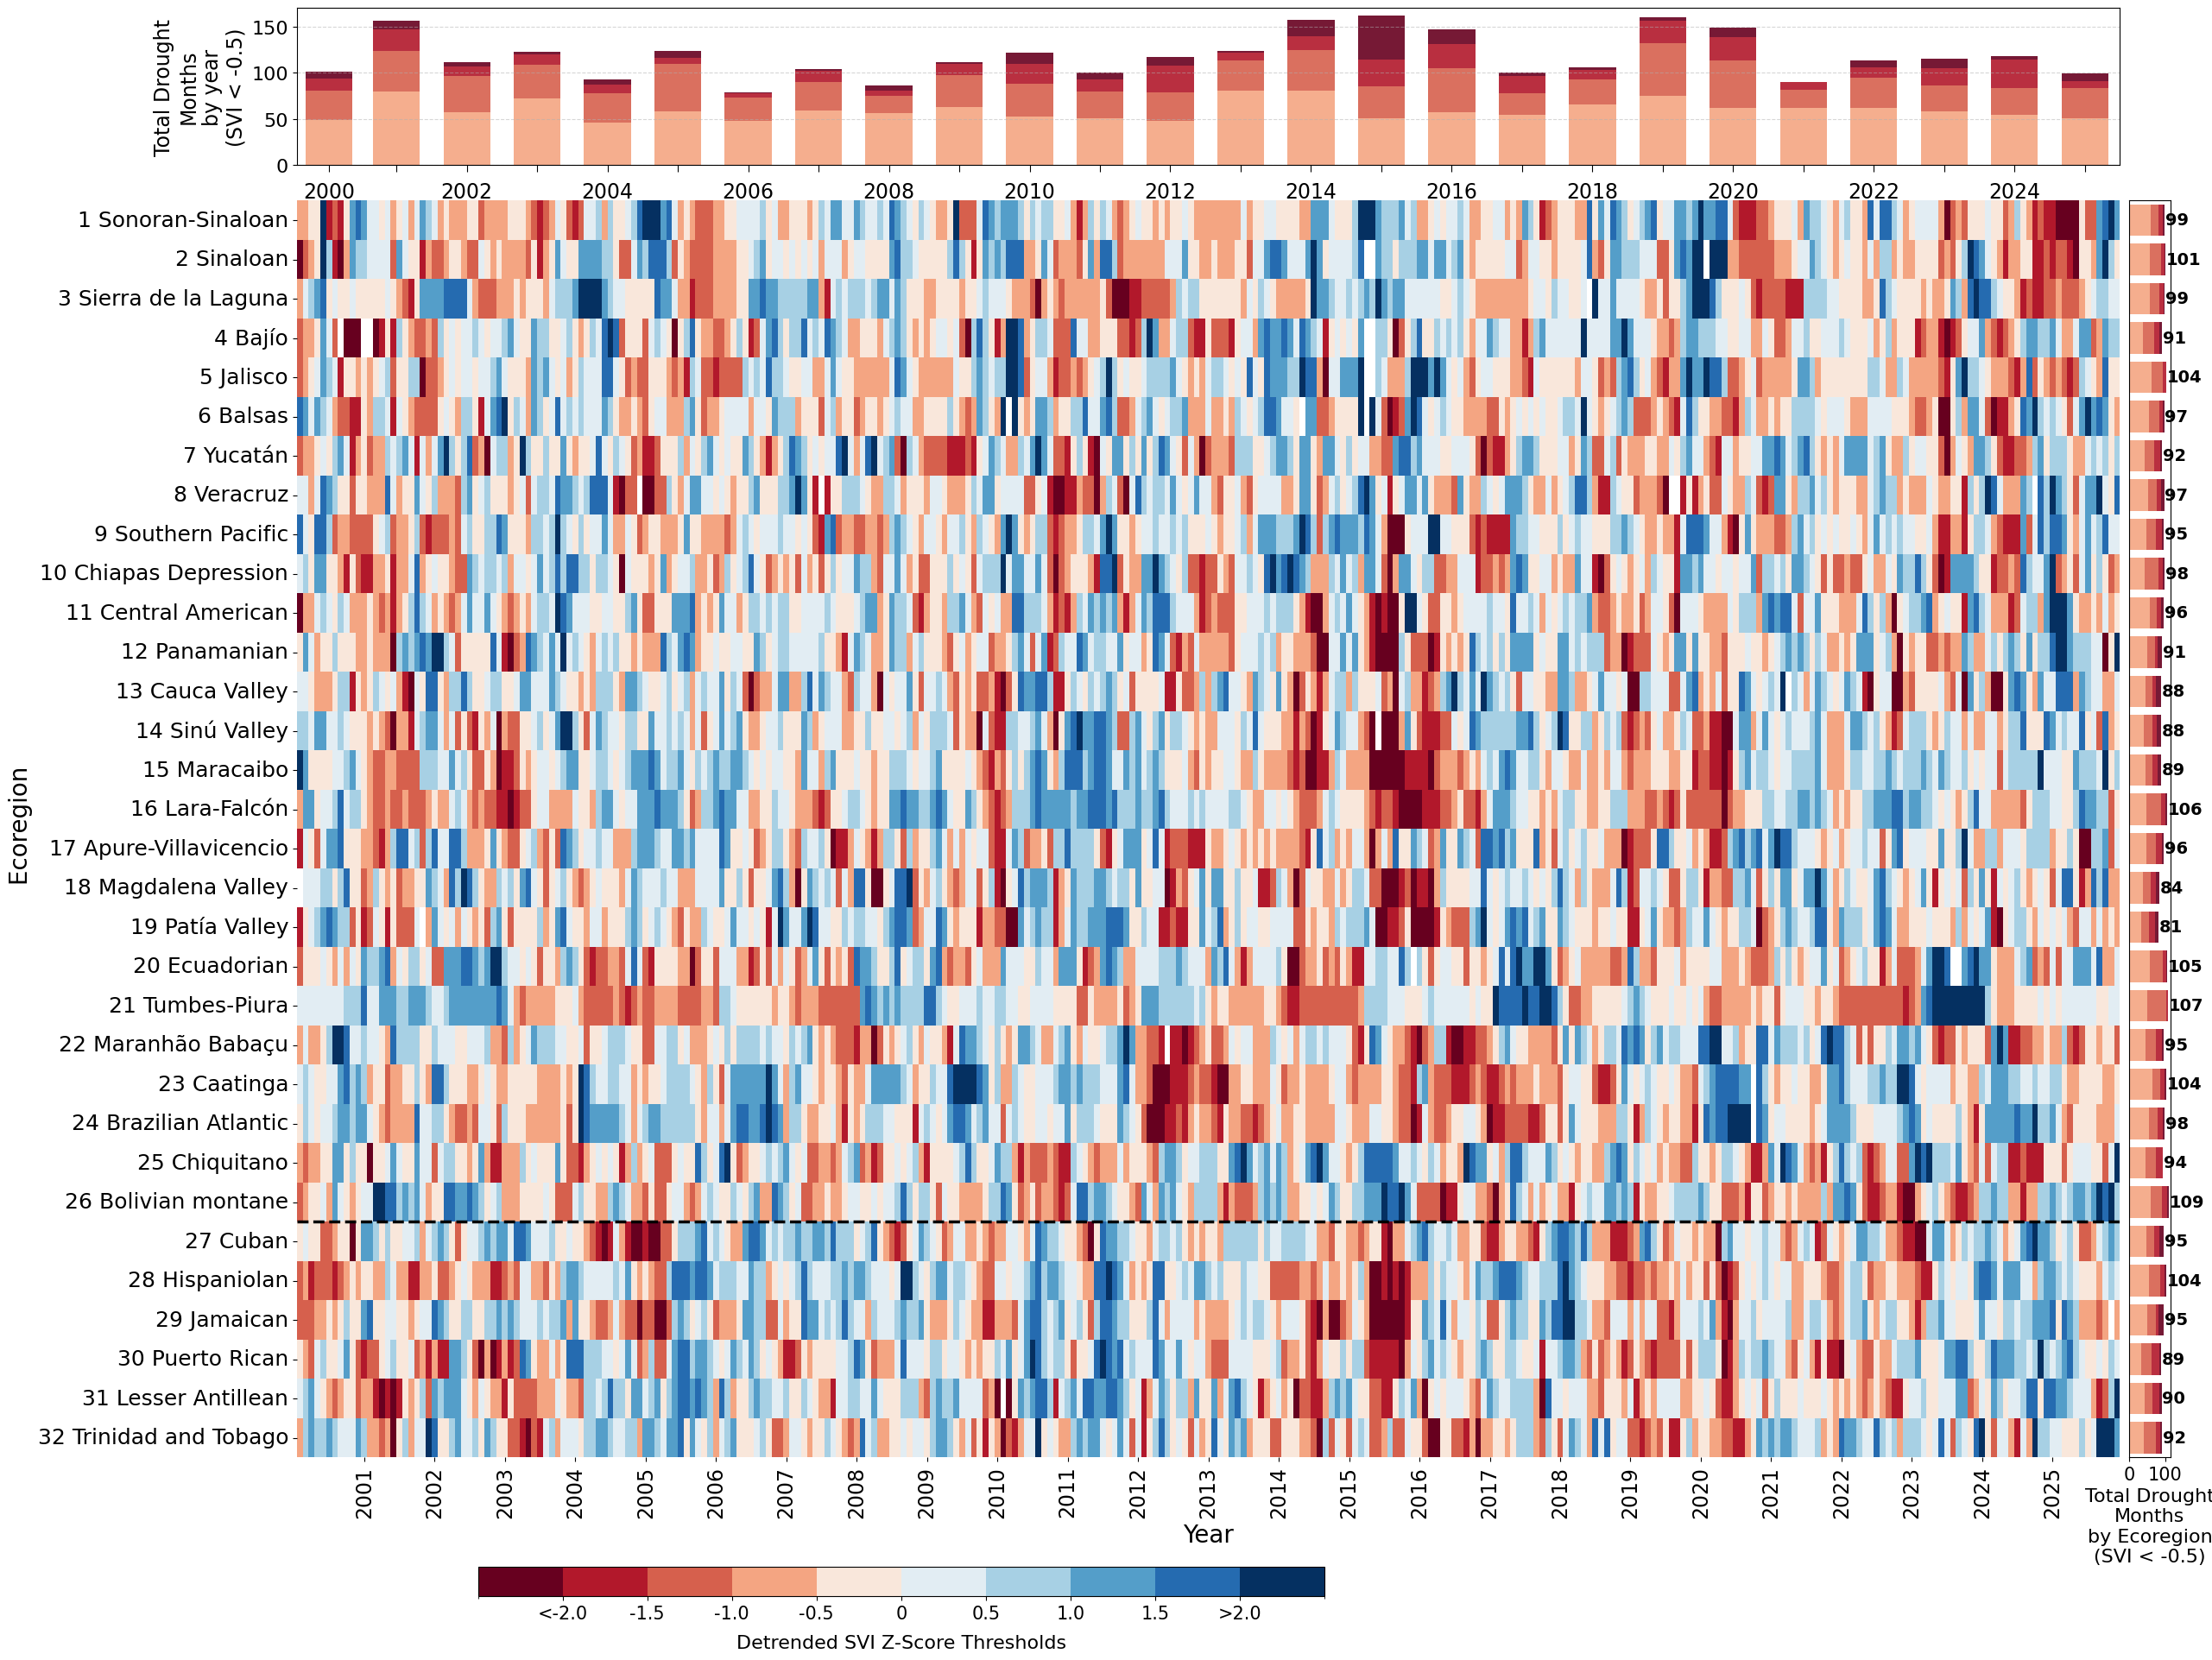

  -> saved outputs/svi_stress_months_by_year.csv
  -> saved outputs/svi_stress_months_by_ecoregion.csv


In [ ]:
desired_feature_order = ECOREGION_ORDER
label_mapping = SHORT_LABELS
bounds_svi = INDEX_BOUNDS
svi_colors_list = INDEX_COLORS
cmap_svi_discrete = mcolors.ListedColormap(svi_colors_list)
norm_svi_discrete = mcolors.BoundaryNorm(bounds_svi, cmap_svi_discrete.N)

def classify_svi(val):
    if pd.isna(val): return np.nan
    if val <= -2.0: return 'SVI < -2'
    elif -2.0 < val <= -1.5: return 'SVI -1.5 to -2'
    elif -1.5 < val <= -1.0: return 'SVI -1 to -1.5'
    elif -1.0 < val <= -0.5: return 'SVI -0.5 to -1'
    else: return 'Normal/Wet'

if 'all_timeseriesv_df' not in globals() or all_timeseriesv_df.empty:
    print("\u26a0 Error: 'all_timeseriesv_df' not found.")
else:
    df_svi_plot = all_timeseriesv_df.copy()
    df_svi_plot['year_month'] = df_svi_plot['date'].dt.to_period('M')
    pivot_svi = df_svi_plot.pivot_table(index='ECO_NAME', columns='year_month', values='SVI_detrended')

    filtered_order = [f for f in desired_feature_order if f in pivot_svi.index]
    pivot_svi = pivot_svi.reindex(filtered_order)

    svi_drought_classes = ['SVI < -2', 'SVI -1.5 to -2', 'SVI -1 to -1.5', 'SVI -0.5 to -1']
    svi_bar_colors = svi_colors_list[:4]

    df_svi_plot['SVI_category'] = df_svi_plot['SVI_detrended'].apply(classify_svi)

    df_top_counts = df_svi_plot[df_svi_plot['SVI_detrended'] < -0.5].groupby(['year', 'SVI_category']).size().unstack(fill_value=0)
    df_top_counts = df_top_counts.reindex(columns=svi_drought_classes, fill_value=0)

    df_right_counts = df_svi_plot[df_svi_plot['SVI_detrended'] < -0.5].groupby(['ECO_NAME', 'SVI_category']).size().unstack(fill_value=0)
    df_right_counts = df_right_counts.reindex(index=filtered_order, columns=svi_drought_classes, fill_value=0)

    fig = plt.figure(figsize=(28, 23))
    gs = gridspec.GridSpec(2, 2, width_ratios=[len(pivot_svi.columns), 7], height_ratios=[4, len(filtered_order)], wspace=0.01, hspace=0.05)

    ax_top = fig.add_subplot(gs[0, 0])
    ax_heatmap = fig.add_subplot(gs[1, 0])
    ax_right = fig.add_subplot(gs[1, 1])

    all_years = sorted(df_top_counts.index.unique())
    year_centers = []
    for yr in all_years:
        indices = [i for i, col in enumerate(pivot_svi.columns) if col.year == yr]
        if indices: year_centers.append(np.mean(indices))

    bottom_top = np.zeros(len(df_top_counts))
    for i, s_class in enumerate(reversed(svi_drought_classes)):
        ax_top.bar(year_centers, df_top_counts[s_class], bottom=bottom_top, color=svi_bar_colors[3-i], width=8, alpha=0.9)
        bottom_top += df_top_counts[s_class].values

    ax_top.set_xlim(-0.5, len(pivot_svi.columns) - 0.5)
    ax_top.set_ylabel('Total Drought\nMonths\nby year\n(SVI < -0.5)', fontsize=17)
    ax_top.tick_params(axis='y', labelsize=16)

    ax_top.set_xticks(year_centers)
    top_x_labels = [str(y) if y % 2 == 0 else '' for y in all_years]
    ax_top.set_xticklabels(top_x_labels, fontsize=17, rotation=0)
    ax_top.tick_params(axis='x', labelbottom=True, labeltop=False, bottom=True, length=6, pad=8)
    ax_top.grid(axis='y', linestyle='--', alpha=0.5)

    sns.heatmap(pivot_svi, cmap=cmap_svi_discrete, norm=norm_svi_discrete, ax=ax_heatmap, cbar=False)
    ax_heatmap.set_ylabel(' Ecoregion', fontsize=20)
    ax_heatmap.set_xlabel('Year', fontsize=20)

    mapped_y_labels = [label_mapping.get(label.get_text(), label.get_text()) for label in ax_heatmap.get_yticklabels()]
    ax_heatmap.set_yticklabels(mapped_y_labels, fontsize=18)

    if 'Bolivian montane dry forests' in pivot_svi.index:
        bol_idx = pivot_svi.index.get_loc('Bolivian montane dry forests')
        ax_heatmap.axhline(y=bol_idx + 1, color='black', linewidth=2.5, linestyle='--')

    tick_pos = [i for i, d in enumerate(pivot_svi.columns) if d.month == 1]
    ax_heatmap.set_xticks(np.array(tick_pos) + 0.5)
    ax_heatmap.set_xticklabels([str(pivot_svi.columns[i].year) for i in tick_pos], rotation=90, fontsize=17)

    left_right = np.zeros(len(filtered_order))
    for i, s_class in enumerate(reversed(svi_drought_classes)):
        ax_right.barh(np.arange(len(filtered_order)), df_right_counts[s_class], left=left_right, color=svi_bar_colors[3-i], height=0.8, alpha=0.9)
        left_right += df_right_counts[s_class].values

    ax_right.set_ylim(len(filtered_order) - 0.5, -0.5)
    ax_right.set_xlabel('Total Drought\nMonths\nby Ecoregion\n(SVI < -0.5)', fontsize=16)
    ax_right.tick_params(axis='x', labelsize=15)
    ax_right.tick_params(axis='y', labelleft=False, length=0)
    for i, total_val in enumerate(left_right):
        if total_val > 0:
            ax_right.text(total_val + 2, i, f'{int(total_val)}', va='center', fontsize=14, fontweight='bold')

    cbar_ax = fig.add_axes([0.2, 0.08, 0.35, 0.015])
    sm = plt.cm.ScalarMappable(cmap=cmap_svi_discrete, norm=norm_svi_discrete)
    cbar_ticks = [-2.0, -1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5, 2.0]
    cbar_labels = ['<-2.0', '-1.5', '-1.0', '-0.5', '0', '0.5', '1.0', '1.5', '>2.0']
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    cbar.ax.set_xticklabels(cbar_labels, fontsize=15)
    cbar.set_label('Detrended SVI Z-Score Thresholds', fontsize=16, labelpad=10)

    plt.subplots_adjust(bottom=0.15)
    plt.savefig(out_path('svi_heatmap_annual_top_bars.png'), dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
if 'all_timeseriesv_df' not in globals() or all_timeseriesv_df.empty:
    print("\u26a0 'all_timeseriesv_df' is not available. Please run the SVI pipeline consolidation first.")
else:
    df_svi_work = all_timeseriesv_df.copy()
    df_svi_work.rename(columns={'SVI_detrended': 'SVI'}, inplace=True)

    # Calculate annual mean SVI per feature
    df_annual_stats_base = df_svi_work.groupby(['ECO_NAME', 'year'])['SVI'].mean().reset_index()

    # Compute descriptive statistics across years for each feature
    df_feature_annual_svi_stats = df_annual_stats_base.groupby('ECO_NAME')['SVI'].agg([
        ('Mean_Annual_SVI', 'mean'),
        ('Std_Dev', 'std'),
        ('Min_Annual', 'min'),
        ('Max_Annual', 'max'),
        ('Median_Annual', 'median')
    ]).reset_index()

  -> saved outputs/svi_annual_statistics.csv


## 5. Soil moisture drought (SSI)

SMAP Enhanced L3 passive soil moisture (`SPL3SMP_E` v5 until 3 Dec 2023, v6 afterwards), morning overpass, retrieval quality bit 0 = 0 and 0.02–0.50 m³ m⁻³. Daily retrievals are averaged into monthly composites, then over each ecoregion with `reduceRegion` at 10 km; if the polygon returns no value for a month, centroid buffers of 25 km and then 50 km are tried. The SSI is the z-score per calendar month, SSI = (SM − μ_m) / σ_m, at a 1-month timescale. Four island ecoregions without valid SMAP retrievals are excluded.

In [ ]:
# Collection 5: Valid from April 2015 to Dec 2023
smap_005 = ee.ImageCollection("NASA/SMAP/SPL3SMP_E/005") \
    .select(['soil_moisture_am', 'retrieval_qual_flag_am']) \
    .filterDate('2015-04-01', '2023-12-04')

# Collection 6: Valid from Dec 2023 to present
smap_006 = ee.ImageCollection("NASA/SMAP/SPL3SMP_E/006") \
    .select(['soil_moisture_am', 'retrieval_qual_flag_am']) \
    .filterDate('2023-12-04', '2025-12-31')

smap_merged = smap_005.merge(smap_006)

def mask_quality(image):
    """Apply retrieval flag mask and physical range filter"""
    quality = image.select('retrieval_qual_flag_am').toInt()
    good_quality = quality.bitwiseAnd(1).eq(0)

    sm = image.select('soil_moisture_am')
    valid_range = sm.gte(0.02).And(sm.lte(0.50))

    return sm.updateMask(good_quality.And(valid_range)) \
             .copyProperties(image, ['system:time_start', 'system:time_end'])

masked = smap_merged.map(mask_quality)

print(f"Total combined images (005 + 006): {masked.size().getInfo()}")

Total combined images (005 + 006): 3838


In [ ]:
# MONTHLY COMPOSITES (2015-2025)

n_features = geometry.size().getInfo()
feature_list = geometry.toList(geometry.size())

def create_monthly_composite(year, month):
    """Generates a monthly mean image or placeholder if no data exists"""
    start = ee.Date.fromYMD(year, month, 1)
    end   = start.advance(1, 'month')

    monthly = masked.filterDate(start, end)

    placeholder = ee.Image.constant(-9999) \
                    .float() \
                    .rename('soil_moisture_am') \
                    .set('year',  year) \
                    .set('month', month) \
                    .set('system:time_start', start.millis())

    composite = ee.Algorithms.If(
        monthly.size().gt(0),
        monthly.mean() \
               .rename('soil_moisture_am') \
               .set('year',  year) \
               .set('month', month) \
               .set('system:time_start', start.millis()),
        placeholder
    )

    return ee.Image(composite)

years  = list(range(2015, 2026))
months = list(range(1, 13))

monthly_images     = [create_monthly_composite(y, m) for y in years for m in months]
monthly_collection = ee.ImageCollection(monthly_images)

print(f"Monthly composites built: {monthly_collection.size().getInfo()} (Apr 2015 - Dec 2025)")

Monthly composites built: 132 (Apr 2015 - Dec 2025)


In [ ]:
# EXTRACTION LOOP (2015-2025)

SMAP_EXCLUDED = {
    i: name for i, name in feature_names.items()
    if name in SMAP_EXCLUDED_NAMES or name not in STUDY_ECOREGIONS
}

def extract_single_image(img, feature_geom):
    centroid = feature_geom.centroid(maxError=100)

    def reduce(geom):
        return img.reduceRegion(
            reducer    = ee.Reducer.mean(),
            geometry   = geom,
            scale      = 10000,
            maxPixels  = 1e9,
            bestEffort = True
        )

    d_poly  = reduce(feature_geom)
    d_buf25 = reduce(centroid.buffer(25000))
    d_buf50 = reduce(centroid.buffer(50000))

    sm_val = ee.Algorithms.If(
        d_poly.contains('soil_moisture_am'),
        d_poly.get('soil_moisture_am'),
        ee.Algorithms.If(
            d_buf25.contains('soil_moisture_am'),
            d_buf25.get('soil_moisture_am'),
            ee.Algorithms.If(
                d_buf50.contains('soil_moisture_am'),
                d_buf50.get('soil_moisture_am'),
                -9999
            )
        )
    )

    return ee.Feature(None, {
        'date':      img.date().format('YYYY-MM-dd'),
        'year':      img.date().get('year'),
        'month':     img.date().get('month'),
        'timestamp': img.date().millis(),
        'sm_raw':    sm_val,
    })

def extract_monthly_timeseries(feature, feature_index, max_retries=3):
    feature_geom  = feature.geometry()
    feature_props = feature.toDictionary().getInfo()
    eco_name      = feature_props.get('ECO_NAME', f'Unknown_ECO_{feature_index}')

    for attempt in range(max_retries):
        try:
            fc = monthly_collection.map(lambda img: extract_single_image(img, feature_geom))
            fc_info = fc.getInfo()
            rows = [f['properties'] for f in fc_info['features']]
            df = pd.DataFrame(rows)
            df['date'] = pd.to_datetime(df['date'])
            df['sm_raw'] = pd.to_numeric(df['sm_raw'], errors='coerce').replace(-9999, np.nan)
            df['sm_pct'] = df['sm_raw'] * 100

            valid_months = df['sm_raw'].notna().sum()
            mean_sm = df['sm_pct'].mean()
            print(f"  ✓ {eco_name} | Valid months: {valid_months}/129") # | Valid months: {valid_months}/132 | Mean SM: {mean_sm:.1f} %
            return df, eco_name
        except Exception as e:
            print(f"    Attempt {attempt+1} failed for {eco_name}: {e}")
            time.sleep(5)
    return None, eco_name

smap_timeseries = {}

print(f"Starting extraction for {n_features} features...")
for i in range(n_features):
    if i in SMAP_EXCLUDED:
        print(f"  - Skipping {i} ({feature_names[i]}): excluded from the SSI analysis.")
        continue

    feature = ee.Feature(feature_list.get(i))
    ts_df, eco_name = extract_monthly_timeseries(feature, i)
    if ts_df is not None:
        smap_timeseries[i] = ts_df

print(f"Extraction complete. Processed {len(smap_timeseries)} features.")

Starting extraction for 33 features...
  - Skipping 0 (Islas Revillagigedo dry forests): excluded from the SSI analysis.
  ✓ Chiquitano dry forests | Valid months: 129/129
  ✓ Lara-Falcón dry forests | Valid months: 129/129
  ✓ Maranhão Babaçu forests | Valid months: 129/129


  ✓ Yucatán dry forests | Valid months: 129/129
  - Skipping 5 (Lesser Antillean dry forests): excluded from the SSI analysis.
  ✓ Apure-Villavicencio dry forests | Valid months: 129/129
  ✓ Central American dry forests | Valid months: 129/129
  ✓ Ecuadorian dry forests | Valid months: 129/129
  ✓ Hispaniolan dry forests | Valid months: 129/129
  ✓ Jalisco dry forests | Valid months: 129/129
  - Skipping 11 (Jamaican dry forests): excluded from the SSI analysis.
  ✓ Magdalena Valley dry forests | Valid months: 129/129
  ✓ Maracaibo dry forests | Valid months: 129/129
  - Skipping 14 (Puerto Rican dry forests): excluded from the SSI analysis.
  ✓ Sierra de la Laguna dry forests | Valid months: 129/129
  ✓ Sinaloan dry forests | Valid months: 129/129
  ✓ Sinú Valley dry forests | Valid months: 129/129
  - Skipping 18 (Trinidad and Tobago dry forest): excluded from the SSI analysis.
  ✓ Bajío dry forests | Valid months: 129/129
  ✓ Balsas dry forests | Valid months: 129/129
  ✓ Bolivian m

In [ ]:
sensor_start = '2015-04-01'
sm_wide = pd.DataFrame()

for idx, df_ts in smap_timeseries.items():
    name = feature_names[idx]
    s = df_ts.set_index('date')['sm_pct'].rename(name)
    sm_wide = pd.concat([sm_wide, s], axis=1)

sm_wide = sm_wide.sort_index()
sm_wide.index = pd.to_datetime(sm_wide.index)

sm_wide = sm_wide[sm_wide.index >= sensor_start]

print(f"Overall missing data: {sm_wide.isna().mean().mean()*100:.2f}%")

Overall missing data: 0.00%


### 5.1 SSI-1 and soil moisture drought months

In [ ]:
# STANDARDIZED SOIL MOISTURE INDEX (SSI) Z-score

if 'sm_wide' not in globals() or sm_wide.empty:
    print("\u26a0 WARNING: 'sm_wide' matrix not found. Please ensure soil moisture extraction and gap-filling are complete.")
elif 'feature_names' not in globals() or not feature_names:
    print("\u26a0 WARNING: 'feature_names' dictionary not found. Cannot map feature IDs.")
else:
    def zscore_standardize(x):
        return (x - x.mean()) / x.std(ddof=1) if x.std() > 0 else 0.0

    ssi_zscore = sm_wide.groupby(sm_wide.index.month).transform(zscore_standardize)

    eco_name_to_id = {v: k for k, v in feature_names.items()}

    all_ssi_zscore_list = []
    for col in ssi_zscore.columns:
        temp_df = ssi_zscore[[col]].reset_index()
        temp_df.columns = ['date', 'SSI_zscore']
        temp_df['ECO_NAME'] = col
        temp_df['feature_id'] = temp_df['ECO_NAME'].map(eco_name_to_id)
        all_ssi_zscore_list.append(temp_df)

    all_ssi_zscore_df = pd.concat(all_ssi_zscore_list, ignore_index=True)

In [ ]:
def classify_ssi_severity(val):
    if pd.isna(val): return np.nan
    if val <= -2.0: return 'Extremely Dry'
    elif -2.0 < val <= -1.5: return 'Severely Dry'
    elif -1.5 < val <= -1.0: return 'Moderately Dry'
    elif -1.0 < val <= -0.5: return 'Mild Dry'
    else: return 'Near Normal/Wet'

if 'all_ssi_zscore_df' in globals():
    drought_cats = ['Mild Dry', 'Moderately Dry', 'Severely Dry', 'Extremely Dry']

    df_ssi1 = all_ssi_zscore_df.copy()
    df_ssi1['Severity'] = df_ssi1['SSI_zscore'].apply(classify_ssi_severity)
    counts_ssi1 = df_ssi1.groupby(['ECO_NAME', 'Severity']).size().unstack(fill_value=0)
    for cat in drought_cats:
        if cat not in counts_ssi1.columns: counts_ssi1[cat] = 0
    counts_ssi1 = counts_ssi1[drought_cats].reset_index()
    save_table(counts_ssi1, 'ssi1_drought_months_by_ecoregion_and_class.csv')

  -> saved outputs/ssi1_drought_months_by_ecoregion_and_class.csv


### 5.2 SSI heatmap and soil moisture drought months (Figure 7)

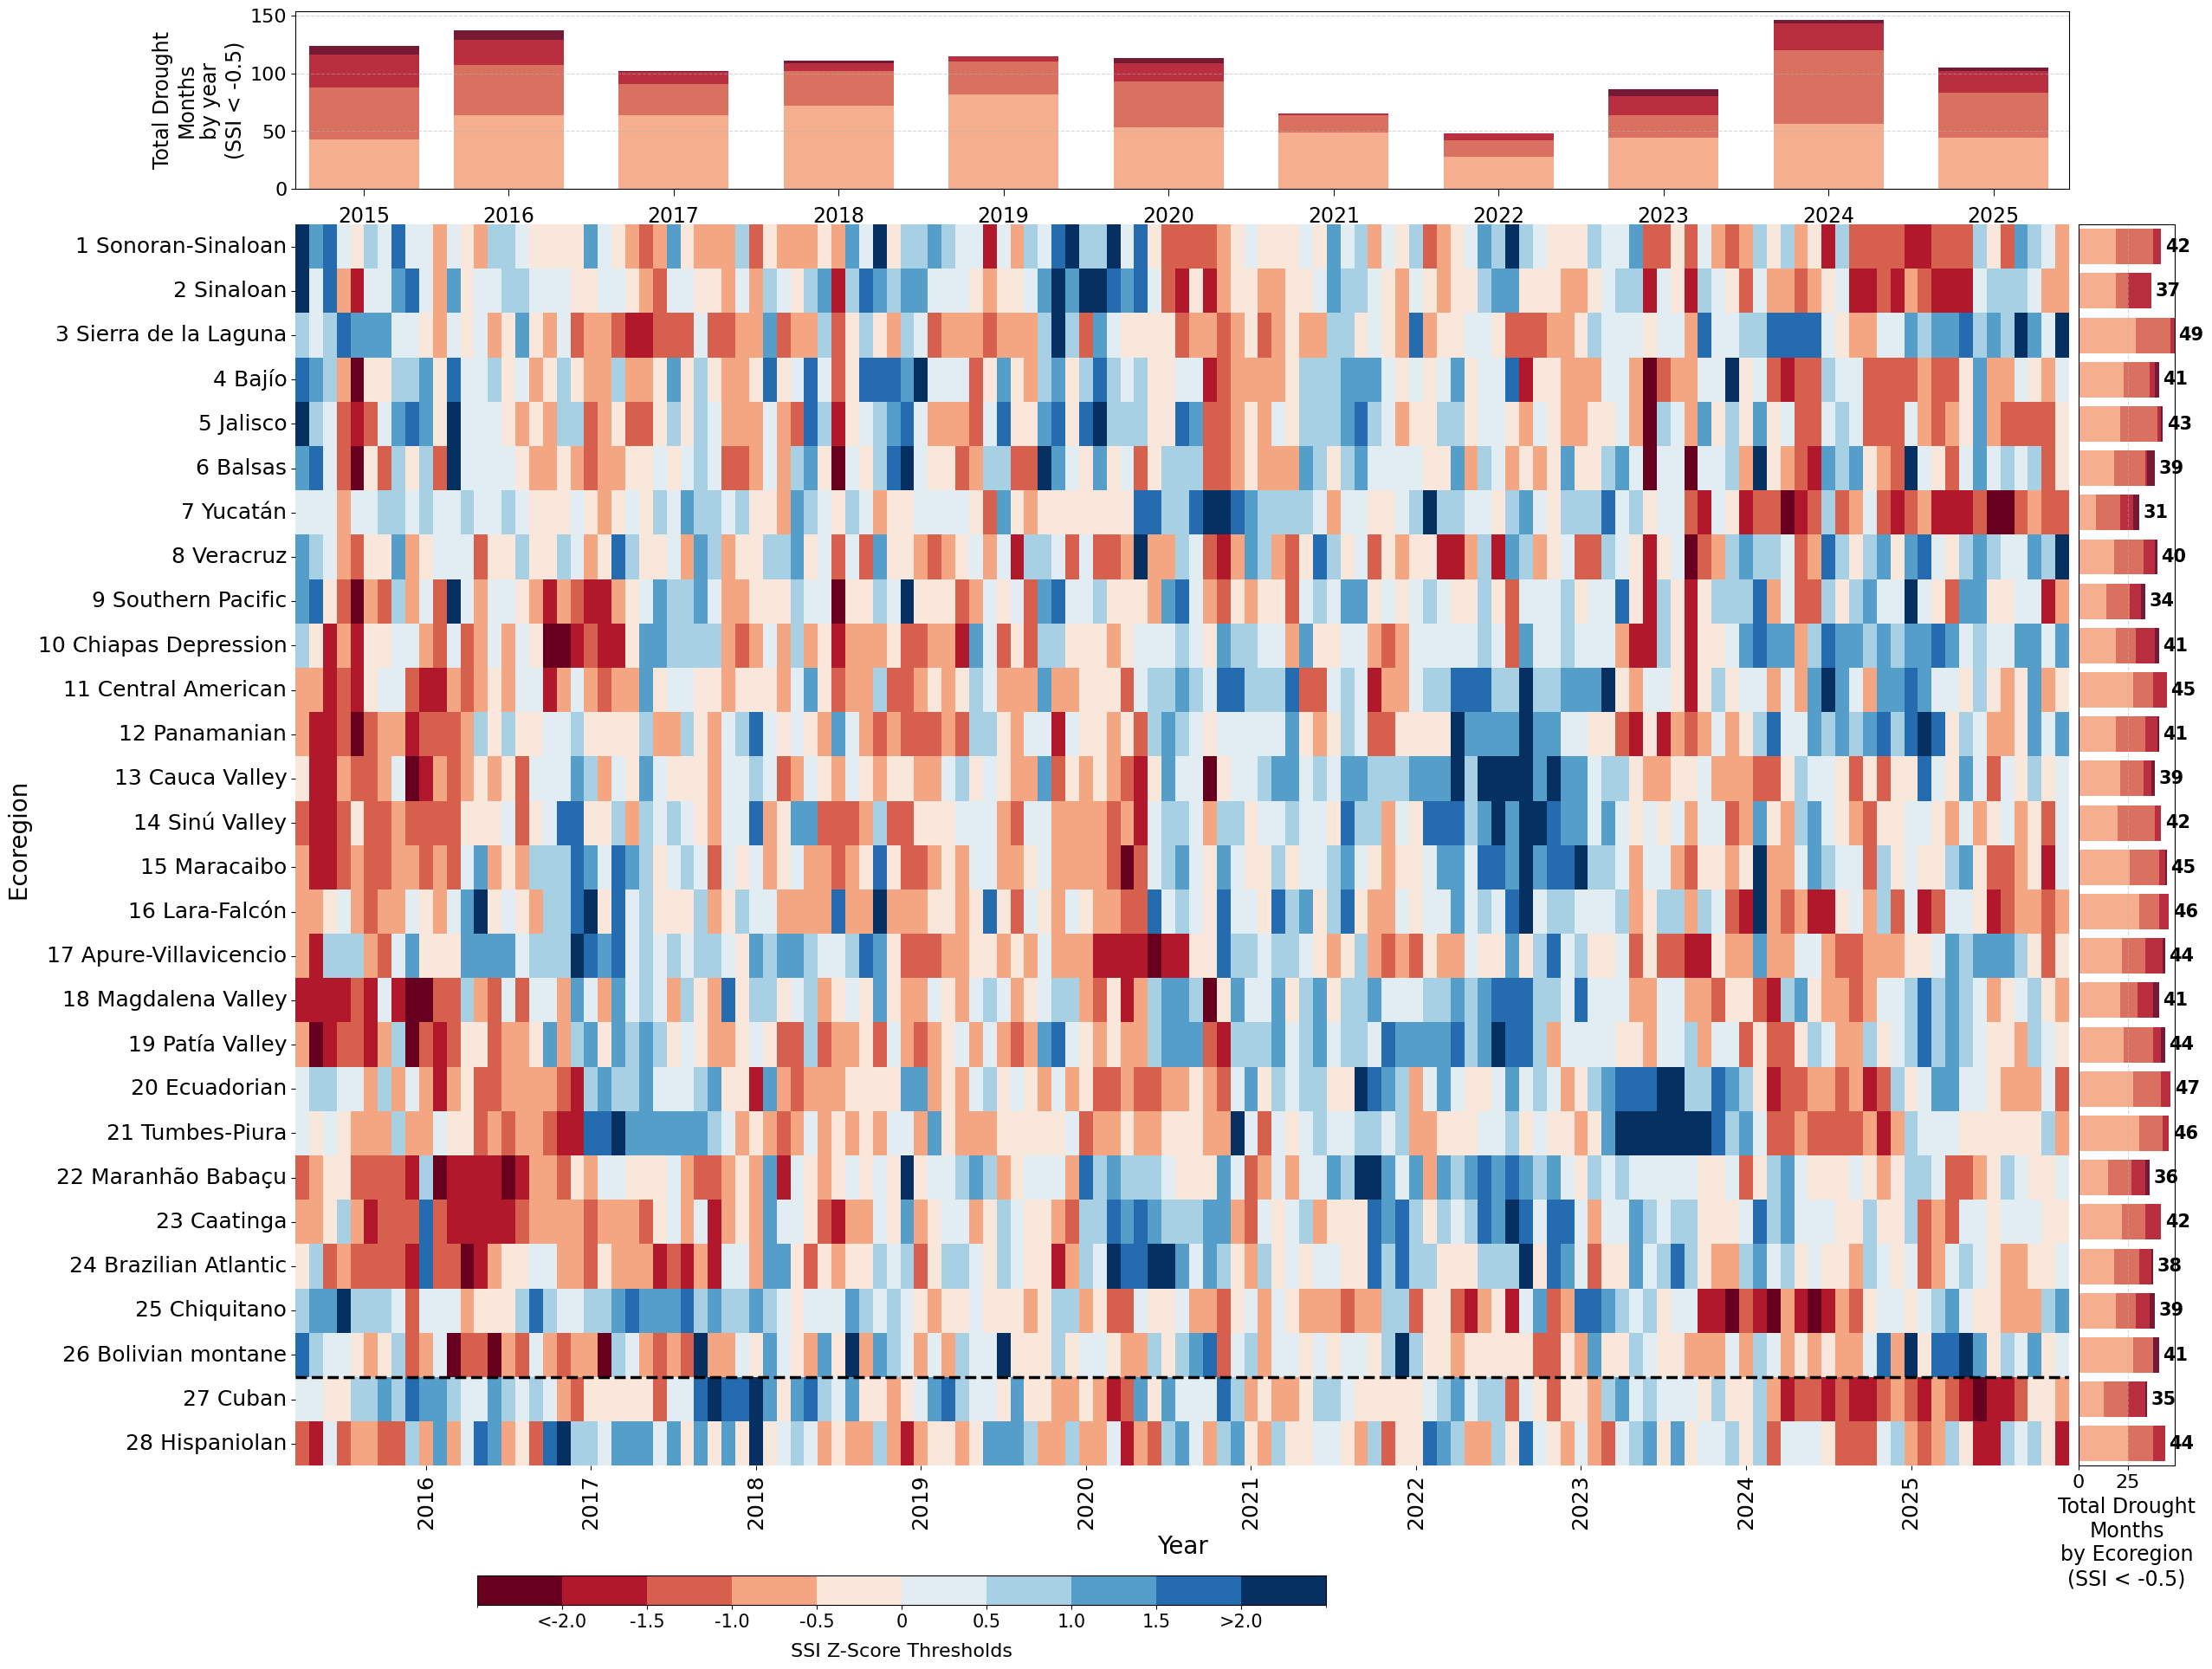

  -> saved outputs/ssi1_drought_months_by_year.csv
  -> saved outputs/ssi1_drought_months_by_ecoregion.csv


In [ ]:
desired_feature_order_smap = ECOREGION_ORDER
label_mapping = SHORT_LABELS
bounds_ssi = INDEX_BOUNDS
ssi_colors_list = INDEX_COLORS
cmap_ssi_discrete = mcolors.ListedColormap(ssi_colors_list)
norm_ssi_discrete = mcolors.BoundaryNorm(bounds_ssi, cmap_ssi_discrete.N)

def classify_ssi_discrete(val):
    if pd.isna(val): return np.nan
    if val <= -2.0: return 'SSI < -2'
    elif -2.0 < val <= -1.5: return 'SSI -1.5 to -2'
    elif -1.5 < val <= -1.0: return 'SSI -1 to -1.5'
    elif -1.0 < val <= -0.5: return 'SSI -0.5 to -1'
    else: return 'Normal/Wet'

if 'all_ssi_zscore_df' not in globals() or all_ssi_zscore_df.empty:
    print("\u26a0 Error: 'all_ssi_zscore_df' not found.")
else:
    df_ssi_plot = all_ssi_zscore_df.copy()
    df_ssi_plot['date_month'] = df_ssi_plot['date'].dt.to_period('M')

    pivot_ssi = df_ssi_plot.pivot_table(index='ECO_NAME', columns='date_month', values='SSI_zscore')

    filtered_order = [f for f in desired_feature_order_smap if f in pivot_ssi.index]
    pivot_ssi = pivot_ssi.reindex(filtered_order)

    ssi_drought_classes = ['SSI < -2', 'SSI -1.5 to -2', 'SSI -1 to -1.5', 'SSI -0.5 to -1']
    ssi_bar_colors = ssi_colors_list[:4]
    descriptive_labels_ssi = {'SSI < -2': 'Extremely Dry', 'SSI -1.5 to -2': 'Severely Dry', 'SSI -1 to -1.5': 'Moderately Dry', 'SSI -0.5 to -1': 'Mild Dry'}

    df_ssi_plot['SSI_category'] = df_ssi_plot['SSI_zscore'].apply(classify_ssi_discrete)

    df_top_counts_ssi = df_ssi_plot[df_ssi_plot['SSI_zscore'] < -0.5].groupby([df_ssi_plot['date'].dt.year, 'SSI_category']).size().unstack(fill_value=0)
    df_top_counts_ssi = df_top_counts_ssi.reindex(columns=ssi_drought_classes, fill_value=0)

    df_right_counts_ssi = df_ssi_plot[df_ssi_plot['SSI_zscore'] < -0.5].groupby(['ECO_NAME', 'SSI_category']).size().unstack(fill_value=0)
    df_right_counts_ssi = df_right_counts_ssi.reindex(index=filtered_order, columns=ssi_drought_classes, fill_value=0)

    all_year_months = pivot_ssi.columns.values
    x_year_centers = {}
    if len(all_year_months) > 0:
        current_year = all_year_months[0].year
        current_year_start_idx = 0
        for i, month_period in enumerate(all_year_months):
            if month_period.year != current_year:
                num_months_in_prev_year = i - current_year_start_idx
                x_year_centers[current_year] = current_year_start_idx + num_months_in_prev_year / 2
                current_year = month_period.year
                current_year_start_idx = i
        num_months_in_last_year = len(all_year_months) - current_year_start_idx
        x_year_centers[current_year] = current_year_start_idx + num_months_in_last_year / 2
    df_top_counts_ssi['x_center_pos'] = df_top_counts_ssi.index.map(x_year_centers)

    fig = plt.figure(figsize=(28, 23))
    gs = gridspec.GridSpec(2, 2, width_ratios=[len(pivot_ssi.columns), 7], height_ratios=[4, len(pivot_ssi)], wspace=0.01, hspace=0.05)

    ax_top = fig.add_subplot(gs[0, 0])
    ax_heatmap = fig.add_subplot(gs[1, 0])
    ax_right = fig.add_subplot(gs[1, 1])

    bottom_top = np.zeros(len(df_top_counts_ssi))
    for i, s_class in enumerate(reversed(ssi_drought_classes)):
        ax_top.bar(df_top_counts_ssi['x_center_pos'], df_top_counts_ssi[s_class], bottom=bottom_top, width=8, color=ssi_bar_colors[3-i], alpha=0.9, label=descriptive_labels_ssi[s_class])
        bottom_top += df_top_counts_ssi[s_class].values

    ax_top.set_ylabel('Total Drought\nMonths\nby year\n(SSI < -0.5)', fontsize=17)
    ax_top.tick_params(axis='y', labelsize=16)
    ax_top.grid(axis='y', linestyle='--', alpha=0.5)
    ax_top.set_xlim(-0.5, len(pivot_ssi.columns) - 0.5)

    all_years_ssi = sorted(df_top_counts_ssi.index.unique())
    ax_top.set_xticks([x_year_centers[y] for y in all_years_ssi])
    top_x_labels = [str(y) for y in all_years_ssi]
    ax_top.set_xticklabels(top_x_labels, fontsize=17, rotation=0)
    ax_top.tick_params(axis='x', labelbottom=True, labeltop=False, bottom=True, length=6, pad=8)

    sns.heatmap(pivot_ssi, cmap=cmap_ssi_discrete, norm=norm_ssi_discrete, cbar=False, ax=ax_heatmap)

    mapped_y_labels = [label_mapping.get(label.get_text(), label.get_text()) for label in ax_heatmap.get_yticklabels()]
    ax_heatmap.set_yticklabels(mapped_y_labels, fontsize=18)

    tick_pos = [i for i, d in enumerate(pivot_ssi.columns) if d.month == 1]
    ax_heatmap.set_xticks(np.array(tick_pos) + 0.5)
    ax_heatmap.set_xticklabels([str(pivot_ssi.columns[i].year) for i in tick_pos], rotation=90, fontsize=18)

    if 'Bolivian montane dry forests' in pivot_ssi.index:
        bol_idx = pivot_ssi.index.get_loc('Bolivian montane dry forests')
        ax_heatmap.axhline(y=bol_idx + 1, color='black', linewidth=2.5, linestyle='--')

    ax_heatmap.set_xlabel('Year', fontsize=20)
    ax_heatmap.set_ylabel(' Ecoregion', fontsize=20)

    left_right = np.zeros(len(filtered_order))
    for i, s_class in enumerate(reversed(ssi_drought_classes)):
        ax_right.barh(np.arange(len(filtered_order)), df_right_counts_ssi[s_class], left=left_right, height=0.8, color=ssi_bar_colors[3-i], alpha=0.9)
        left_right += df_right_counts_ssi[s_class].values

    for i, total_val in enumerate(left_right):
        if total_val > 0:
            ax_right.text(total_val + 2, i, f'{int(total_val)}', va='center', fontsize=15, fontweight='bold')
    ax_right.set_ylim(len(filtered_order) - 0.5, -0.5)
    ax_right.set_xlabel('Total Drought\nMonths\nby Ecoregion\n(SSI < -0.5)', fontsize=17)
    ax_right.tick_params(axis='x', labelsize=16)
    ax_right.tick_params(axis='y', labelleft=False, length=0)
    ax_right.grid(axis='x', linestyle='--', alpha=0.5)

    cbar_ax = fig.add_axes([0.2, 0.08, 0.35, 0.015])
    sm = plt.cm.ScalarMappable(cmap=cmap_ssi_discrete, norm=norm_ssi_discrete)
    cbar_ticks = [-2.0, -1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5, 2.0]
    cbar_labels = ['<-2.0', '-1.5', '-1.0', '-0.5', '0', '0.5', '1.0', '1.5', '>2.0']
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    cbar.ax.set_xticklabels(cbar_labels, fontsize=15)
    cbar.set_label('SSI Z-Score Thresholds', fontsize=16, labelpad=10)

    plt.subplots_adjust(bottom=0.15)
    plt.savefig(out_path('ssi_heatmap_annual_top_bars.png'), dpi=300, bbox_inches='tight')
    plt.show()

## 6. Cross-index coupling and drought propagation

All three indices over their common period (April 2015 – December 2024) for the 28 ecoregions with SSI data.

In [ ]:
#Prepare a SPEI, SVI, and SSI into a master DataFrame (Overlapping Period Only)

spei_cols = ['spei_01', 'spei_03', 'spei_12', 'spei_24']
df_spei_selected = all_timeseries_df[['date', 'feature_id'] + [c for c in spei_cols if c in all_timeseries_df.columns]].copy()
df_spei_selected['date'] = pd.to_datetime(df_spei_selected['date'])

# SVI data
sevi_cols = ['SVI_raw', 'SVI_detrended']
df_sevi_selected = all_timeseriesv_df[['date', 'feature_id'] + [c for c in sevi_cols if c in all_timeseriesv_df.columns]].copy()
df_sevi_selected['date'] = pd.to_datetime(df_sevi_selected['date'])

# SSI data
eco_name_to_id = {v: k for k, v in feature_names.items()}
df_ssi_long = all_ssi_zscore_df.rename(columns={'SSI_zscore': 'SSI-1'})

# Join SPEI and sEVI
df_all_indices = pd.merge(df_spei_selected, df_sevi_selected, on=['date', 'feature_id'], how='inner')

# Join with SSI
df_all_indices = pd.merge(df_all_indices, df_ssi_long, on=['date', 'feature_id'], how='inner')

df_all_indices['ECO_NAME'] = df_all_indices['feature_id'].map(feature_names)
df_all_indices = df_all_indices.sort_values(['feature_id', 'date']).reset_index(drop=True)

print(f"Date Range: {df_all_indices['date'].min().date()} to {df_all_indices['date'].max().date()}")

Date Range: 2015-04-01 to 2024-12-01


In [ ]:
# Lags below are applied by shifting rows, which assumes a complete, gap-free monthly
# series for every ecoregion over the common period. This check reports any gaps.
expected_months = pd.date_range(df_all_indices['date'].min(), df_all_indices['date'].max(), freq='MS')
gap_report = []
for eco, g in df_all_indices.groupby('ECO_NAME'):
    complete = g.dropna(subset=['spei_01', 'SVI_detrended', 'SSI-1'])
    gap_report.append({
        'ECO_NAME': eco,
        'months_expected': len(expected_months),
        'months_with_rows': g['date'].nunique(),
        'months_complete': len(complete),
    })
gap_report = pd.DataFrame(gap_report)
gappy = gap_report[gap_report['months_complete'] < gap_report['months_expected']]
print(f"Ecoregions: {len(gap_report)} | months expected: {len(expected_months)}")
if gappy.empty:
    print("✓ No gaps: row shifts equal calendar-month lags for every ecoregion.")
else:
    print(f"⚠ {len(gappy)} ecoregion(s) have missing months; row shifts there are not exact calendar lags:")
    display(gappy)

Ecoregions: 28 | months expected: 117
⚠ 11 ecoregion(s) have missing months; row shifts there are not exact calendar lags:


,ECO_NAME,months_expected,months_with_rows,months_complete
1,Bajío dry forests,117,117,115
2,Balsas dry forests,117,117,116
4,Brazilian Atlantic dry forests,117,117,116
5,Caatinga,117,117,116
6,Cauca Valley dry forests,117,117,116
11,Ecuadorian dry forests,117,117,114
13,Jalisco dry forests,117,117,115
20,Sierra de la Laguna dry forests,117,117,116
21,Sinaloan dry forests,117,117,114
22,Sinú Valley dry forests,117,117,116


### 6.1 Spearman coupling at zero lag (Figure 8)

Spearman rank correlations between SPEI-1, SSI-1 and SVI; Benjamini–Hochberg FDR correction across all ecoregions and index pairs together.

In [ ]:
indices_to_test = ['spei_01', 'SVI_detrended', 'SSI-1']
pairs = [
    ('spei_01', 'SVI_detrended'),
    ('SSI-1', 'SVI_detrended'),
    ('spei_01', 'SSI-1')
]

raw_results = []

for eco_name, group in df_all_indices.groupby('ECO_NAME'):
    valid = group[indices_to_test].dropna()

    if len(valid) > 5:
        for var1, var2 in pairs:
            r, p = spearmanr(valid[var1], valid[var2])
            raw_results.append({
                'ECO_NAME': eco_name,
                'Comparison': f"{var1}_vs_{var2}",
                'Spearman_r': r,
                'p_value': p
            })

df_fdr = pd.DataFrame(raw_results)

if not df_fdr.empty:
    _, p_adj, _, _ = multipletests(df_fdr['p_value'], alpha=0.05, method='fdr_bh')
    df_fdr['p_value_adj'] = p_adj
    df_fdr['is_significant_fdr'] = df_fdr['p_value_adj'] < 0.05

    # 4. Filter and display significant results only
    sig_only = df_fdr[df_fdr['is_significant_fdr']].sort_values('p_value_adj')

    print(f"Significant relationships after FDR correction: {len(sig_only)}")

Significant relationships after FDR correction: 76
  -> saved outputs/spearman_zero_lag_fdr.csv


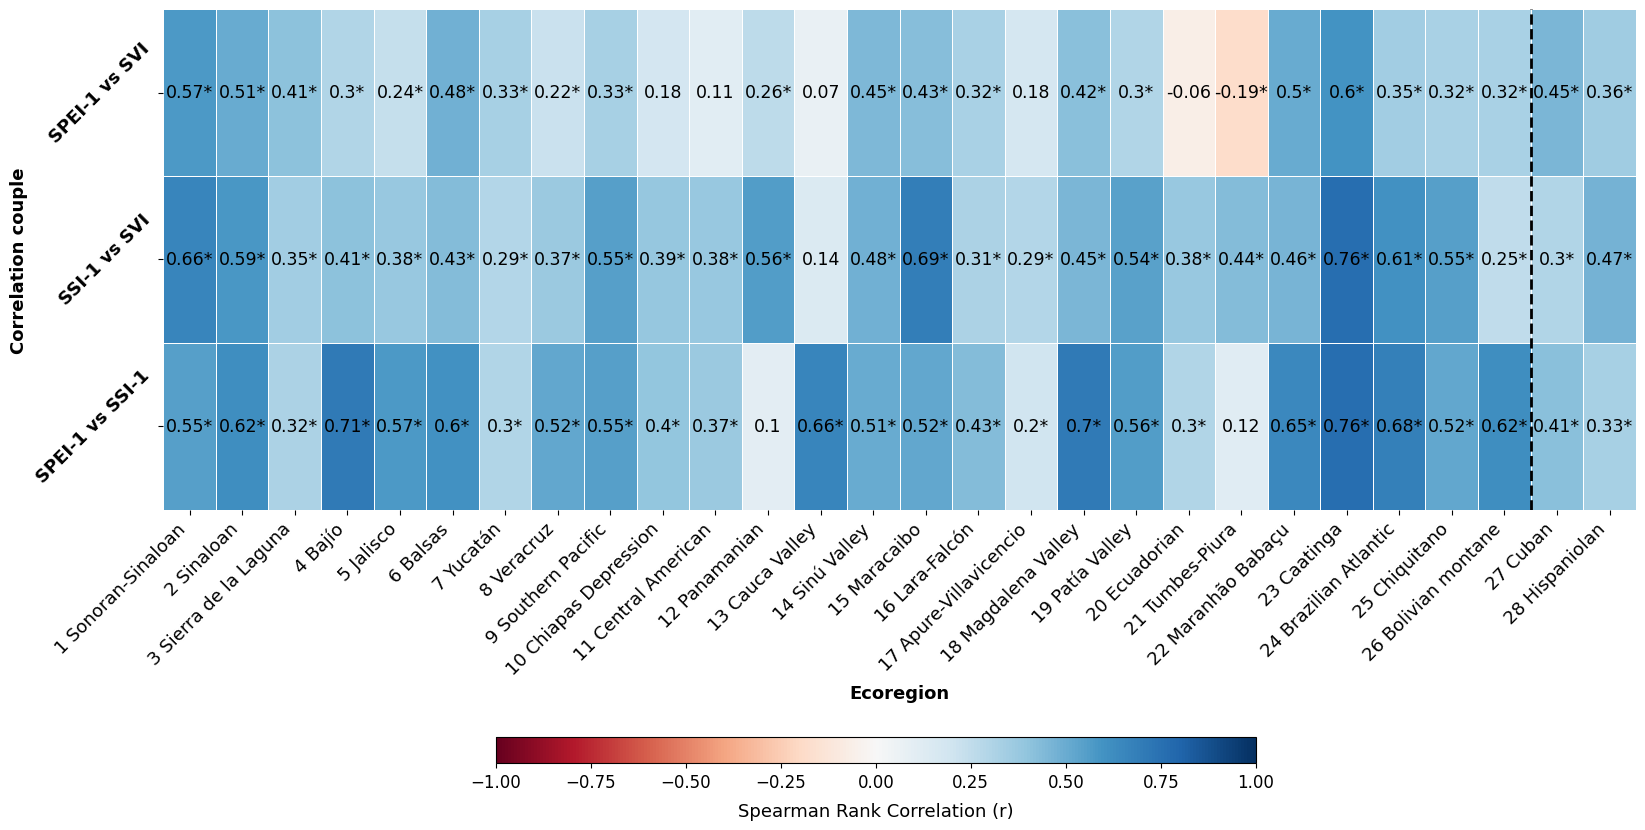

In [ ]:
if 'df_fdr' in globals() and not df_fdr.empty:
    df_heatmap_r = df_fdr.pivot(index='Comparison', columns='ECO_NAME', values='Spearman_r')
    df_heatmap_p = df_fdr.pivot(index='Comparison', columns='ECO_NAME', values='p_value_adj')

    col_order = ['spei_01_vs_SVI_detrended', 'SSI-1_vs_SVI_detrended', 'spei_01_vs_SSI-1']
    display_labels = ['SPEI-1 vs SVI', 'SSI-1 vs SVI', 'SPEI-1 vs SSI-1']

    df_heatmap_r = df_heatmap_r.reindex(index=col_order)
    df_heatmap_p = df_heatmap_p.reindex(index=col_order)

    df_heatmap_r.index = display_labels
    df_heatmap_p.index = display_labels

    desired_cols = [f for f in ECOREGION_ORDER if f in df_heatmap_r.columns]

    df_heatmap_r = df_heatmap_r.reindex(columns=desired_cols)
    df_heatmap_p = df_heatmap_p.reindex(columns=desired_cols)

    label_mapping = SHORT_LABELS

    short_cols = [label_mapping.get(c, c) for c in df_heatmap_r.columns]

    annot_matrix = df_heatmap_r.round(2).astype(str)
    for i in range(df_heatmap_p.shape[0]):
        for j in range(df_heatmap_p.shape[1]):
            if df_heatmap_p.iloc[i, j] < 0.05:
                annot_matrix.iloc[i, j] = annot_matrix.iloc[i, j] + "*"

    fig, ax = plt.subplots(figsize=(19, 6.5))

    sns.heatmap(
        df_heatmap_r,
        annot=annot_matrix,
        fmt="",
        cmap='RdBu',
        center=0,
        vmin=-1, vmax=1,
        linewidths=0.5,
        ax=ax,
        cbar=False,
        annot_kws={'size': 12.5, 'color': 'black'}
    )

    ax.set_xticklabels(short_cols, rotation=45, ha='right', fontsize=13)
    ax.set_yticklabels(display_labels, rotation=45, fontsize=13, fontweight='bold')
    ax.set_ylabel('Correlation couple', fontsize=13, fontweight='bold')
    ax.set_xlabel('Ecoregion', fontsize=13, fontweight='bold')

    if LAST_CONTINENTAL in df_heatmap_r.columns:
        idx = df_heatmap_r.columns.get_loc(LAST_CONTINENTAL)
        ax.axvline(x=idx + 1, color='black', linewidth=2, linestyle='--')

    cbar_ax = fig.add_axes([0.3, -0.28, 0.4, 0.04])
    sm = plt.cm.ScalarMappable(cmap='RdBu', norm=plt.Normalize(vmin=-1, vmax=1))
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Spearman Rank Correlation (r)', fontsize=13, labelpad=8)
    cbar.ax.tick_params(labelsize=12)

    plt.savefig(out_path('fdr_spearman_ecoregions_columns.png'), dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Error: df_fdr is not defined or empty. Please run the correlation calculation block first.")

### 6.2 Optimal lags (Table 3)

For each ecoregion and index pair, the optimal lag (0–6 months) is the lag with the highest Spearman coefficient. Its p-value is FDR-corrected (Benjamini–Hochberg) within each index pair across ecoregions.

In [ ]:
def calculate_spearman_lag(df, predictor, target, max_lag=MAX_LAG):
    best_r = -1
    best_lag = 0
    best_p = np.nan

    valid_df = df[['date', predictor, target]].dropna()
    if len(valid_df) < 12:
        return np.nan, np.nan, np.nan

    for lag in range(0, max_lag + 1):
        x = valid_df[predictor].iloc[:len(valid_df)-lag].values if lag > 0 else valid_df[predictor].values
        y = valid_df[target].iloc[lag:].values if lag > 0 else valid_df[target].values

        if len(x) > 1:
            r, p = sp_stats.spearmanr(x, y)
            if r > best_r:
                best_r = r
                best_lag = lag
                best_p = p

    return best_lag, round(best_r, 3), round(best_p, 4)

propagation_results = []

print("Drought propagation lags (Atmosphere -> Soil -> Vegetation) with FDR correction...")

for eco_name, group in df_all_indices.groupby('ECO_NAME'):
    group = group.sort_values('date')

    lag_spei1_ssi1, r_spei1_ssi1, p_spei1_ssi1 = calculate_spearman_lag(group, 'spei_01', 'SSI-1')
    lag_spei1_svi, r_spei1_svi, p_spei1_svi   = calculate_spearman_lag(group, 'spei_01', 'SVI_detrended')
    lag_ssi1_svi, r_ssi1_svi, p_ssi1_svi   = calculate_spearman_lag(group, 'SSI-1', 'SVI_detrended')

    propagation_results.append({
        'ECO_NAME': eco_name,
        'Lag_SPEI1_to_SSI1': lag_spei1_ssi1,
        'R_SPEI1_to_SSI1': r_spei1_ssi1,
        'P_SPEI1_to_SSI1': p_spei1_ssi1,
        'Lag_SPEI1_to_SVI': lag_spei1_svi,
        'R_SPEI1_to_SVI': r_spei1_svi,
        'P_SPEI1_to_SVI': p_spei1_svi,
        'Lag_SSI1_to_SVI': lag_ssi1_svi,
        'R_SSI1_to_SVI': r_ssi1_svi,
        'P_SSI1_to_SVI': p_ssi1_svi
    })

df_propagation_lags = pd.DataFrame(propagation_results)

for col in ['P_SPEI1_to_SSI1', 'P_SPEI1_to_SVI', 'P_SSI1_to_SVI']:
    original_p_values = df_propagation_lags[col].dropna()
    if not original_p_values.empty:
        _, p_adjusted_col, _, _ = multipletests(original_p_values.tolist(), alpha=0.05, method='fdr_bh')
        df_propagation_lags.loc[original_p_values.index, f'{col}_adj'] = p_adjusted_col
        df_propagation_lags[f'{col}_sig'] = df_propagation_lags[f'{col}_adj'] < 0.05
    else:
        df_propagation_lags[f'{col}_adj'] = np.nan
        df_propagation_lags[f'{col}_sig'] = False

Drought propagation lags (Atmosphere -> Soil -> Vegetation) with FDR correction...


,ECO_NAME,Lag_SPEI1_to_SSI1,R_SPEI1_to_SSI1,P_SPEI1_to_SSI1,Lag_SPEI1_to_SVI,R_SPEI1_to_SVI,P_SPEI1_to_SVI,Lag_SSI1_to_SVI,R_SSI1_to_SVI,P_SSI1_to_SVI,P_SPEI1_to_SSI1_adj,P_SPEI1_to_SSI1_sig,P_SPEI1_to_SVI_adj,P_SPEI1_to_SVI_sig,P_SSI1_to_SVI_adj,P_SSI1_to_SVI_sig
0,Apure-Villavicencio dry forests,0,0.199,0.0311,1,0.270,0.0034,0,0.292,0.0014,0.033492,True,0.004139,True,0.001452,True
1,Bajío dry forests,0,0.716,0.0000,1,0.475,0.0000,1,0.483,0.0000,0.000000,True,0.000000,True,0.000000,True
2,Balsas dry forests,0,0.609,0.0000,1,0.566,0.0000,0,0.431,0.0000,0.000000,True,0.000000,True,0.000000,True
3,Bolivian montane dry forests,0,0.623,0.0000,1,0.470,0.0000,1,0.412,0.0000,0.000000,True,0.000000,True,0.000000,True
4,Brazilian Atlantic dry forests,0,0.685,0.0000,1,0.467,0.0000,1,0.720,0.0000,0.000000,True,0.000000,True,0.000000,True


  -> saved outputs/drought_propagation_lags_fdr.csv


### 6.3 Moving-block bootstrap confidence intervals (Table 3)

95% percentile confidence intervals for the FDR-significant optimal-lag correlations, from a moving-block bootstrap with `N_BOOT_CI` resamples.

In [ ]:
def block_bootstrap_correlation(df_eco, predictor, target, lag, block_size_override=None, n_bootstraps=N_BOOT_CI):
    """
    Calculates bootstrapped Spearman correlations for a given predictor, target, and lag.

    Args:
        df_eco (pd.DataFrame): Time series data for a single eco-region.
        predictor (str): Name of the predictor column.
        target (str): Name of the target column.
        lag (int): The specific lag in months (target lags predictor by this amount).
        block_size_override (int, optional): Specific block size to use. If None, it's calculated
                                            as N^(1/3) where N is effective series length.
        n_bootstraps (int): Number of bootstrap samples to generate.

    Returns:
        np.array: An array of bootstrapped Spearman correlation coefficients.
    """
    df_temp = df_eco[['date', predictor, target]].dropna().sort_values('date')

    x_orig = df_temp[predictor].iloc[:-lag].values if lag > 0 else df_temp[predictor].values
    y_orig = df_temp[target].iloc[lag:].values if lag > 0 else df_temp[target].values

    n = len(x_orig)

    if n < 2:
        return np.array([])

    # Determine block size
    if block_size_override is not None:
        block_size = block_size_override
    else:
        block_size = max(2, int(n**(1/3)))

    if block_size > n:
        block_size = n

    n_blocks = int(np.ceil(n / block_size))

    bootstrapped_correlations = []

    for _ in range(n_bootstraps):
        resampled_indices_flat = []
        for _ in range(n_blocks):

            if n >= block_size:
                random_block_start = np.random.randint(0, n - block_size + 1)
            else:
                random_block_start = 0

            resampled_indices_flat.extend(np.arange(random_block_start, min(random_block_start + block_size, n)))

        resampled_indices = np.array(resampled_indices_flat[:n])

        if len(np.unique(resampled_indices)) < 2:
            bootstrapped_correlations.append(np.nan)
            continue

        x_boot = x_orig[resampled_indices]
        y_boot = y_orig[resampled_indices]

        if len(np.unique(x_boot)) < 2 or len(np.unique(y_boot)) < 2:
            bootstrapped_correlations.append(np.nan)
            continue

        try:
            r, _ = spearmanr(x_boot, y_boot)
            bootstrapped_correlations.append(r)
        except ValueError:
            bootstrapped_correlations.append(np.nan)

    bootstrapped_correlations = np.array(bootstrapped_correlations)
    bootstrapped_correlations = bootstrapped_correlations[~np.isnan(bootstrapped_correlations)]

    return bootstrapped_correlations

df_propagation_lags_ci = df_propagation_lags.copy()

df_propagation_lags_ci['R_SPEI1_to_SSI1_CI_low'] = np.nan
df_propagation_lags_ci['R_SPEI1_to_SSI1_CI_high'] = np.nan
df_propagation_lags_ci['R_SPEI1_to_SVI_CI_low'] = np.nan
df_propagation_lags_ci['R_SPEI1_to_SVI_CI_high'] = np.nan
df_propagation_lags_ci['R_SSI1_to_SVI_CI_low'] = np.nan
df_propagation_lags_ci['R_SSI1_to_SVI_CI_high'] = np.nan

print("Calculating block-bootstrap confidence intervals for lag correlations...")
np.random.seed(RANDOM_SEED)
block_sizes_used = {}

for index, row in df_propagation_lags.iterrows():
    eco_name = row['ECO_NAME']
    df_eco = df_all_indices[df_all_indices['ECO_NAME'] == eco_name].copy()

    max_len_for_bootstrap = len(df_eco[['spei_01', 'SSI-1', 'SVI_detrended']].dropna())
    if max_len_for_bootstrap > 0:
        block_size_for_eco = max(2, int(max_len_for_bootstrap**(1/3)))
    else:
        block_size_for_eco = 5
    block_sizes_used[eco_name] = block_size_for_eco

    # SPEI1 to SSI1
    if row['P_SPEI1_to_SSI1_sig']:
        boot_corrs = block_bootstrap_correlation(
            df_eco, 'spei_01', 'SSI-1', row['Lag_SPEI1_to_SSI1'], block_size_override=block_size_for_eco
        )
        if len(boot_corrs) >= 20:
            lower = np.percentile(boot_corrs, 2.5)
            upper = np.percentile(boot_corrs, 97.5)
            df_propagation_lags_ci.loc[index, 'R_SPEI1_to_SSI1_CI_low'] = round(lower, 3)
            df_propagation_lags_ci.loc[index, 'R_SPEI1_to_SSI1_CI_high'] = round(upper, 3)

    # SPEI1 to SVI
    if row['P_SPEI1_to_SVI_sig']:
        boot_corrs = block_bootstrap_correlation(
            df_eco, 'spei_01', 'SVI_detrended', row['Lag_SPEI1_to_SVI'], block_size_override=block_size_for_eco
        )
        if len(boot_corrs) >= 20:
            lower = np.percentile(boot_corrs, 2.5)
            upper = np.percentile(boot_corrs, 97.5)
            df_propagation_lags_ci.loc[index, 'R_SPEI1_to_SVI_CI_low'] = round(lower, 3)
            df_propagation_lags_ci.loc[index, 'R_SPEI1_to_SVI_CI_high'] = round(upper, 3)

    # SSI1 to SVI
    if row['P_SSI1_to_SVI_sig']:
        boot_corrs = block_bootstrap_correlation(
            df_eco, 'SSI-1', 'SVI_detrended', row['Lag_SSI1_to_SVI'], block_size_override=block_size_for_eco
        )
        if len(boot_corrs) >= 20:
            lower = np.percentile(boot_corrs, 2.5)
            upper = np.percentile(boot_corrs, 97.5)
            df_propagation_lags_ci.loc[index, 'R_SSI1_to_SVI_CI_low'] = round(lower, 3)
            df_propagation_lags_ci.loc[index, 'R_SSI1_to_SVI_CI_high'] = round(upper, 3)


print("✓ Block-bootstrap confidence intervals calculated.")

display_cols = [
    'ECO_NAME',
    'R_SPEI1_to_SSI1', 'R_SPEI1_to_SSI1_CI_low', 'R_SPEI1_to_SSI1_CI_high', 'P_SPEI1_to_SSI1_sig',
    'R_SPEI1_to_SVI', 'R_SPEI1_to_SVI_CI_low', 'R_SPEI1_to_SVI_CI_high', 'P_SPEI1_to_SVI_sig',
    'R_SSI1_to_SVI', 'R_SSI1_to_SVI_CI_low', 'R_SSI1_to_SVI_CI_high', 'P_SSI1_to_SVI_sig',
]

print("\nPropagation Lags with 95% Block-Bootstrap Confidence Intervals (for significant correlations):")
display(df_propagation_lags_ci[display_cols].dropna(how='all', subset=display_cols[1:]))

Calculating block-bootstrap confidence intervals for lag correlations...
✓ Block-bootstrap confidence intervals calculated.

Propagation Lags with 95% Block-Bootstrap Confidence Intervals (for significant correlations):


,ECO_NAME,R_SPEI1_to_SSI1,R_SPEI1_to_SSI1_CI_low,R_SPEI1_to_SSI1_CI_high,P_SPEI1_to_SSI1_sig,R_SPEI1_to_SVI,R_SPEI1_to_SVI_CI_low,R_SPEI1_to_SVI_CI_high,P_SPEI1_to_SVI_sig,R_SSI1_to_SVI,R_SSI1_to_SVI_CI_low,R_SSI1_to_SVI_CI_high,P_SSI1_to_SVI_sig
0,Apure-Villavicencio dry forests,0.199,0.016,0.377,True,0.270,0.086,0.433,True,0.292,0.051,0.508,True
1,Bajío dry forests,0.716,0.597,0.793,True,0.475,0.321,0.608,True,0.483,0.311,0.638,True
2,Balsas dry forests,0.609,0.469,0.713,True,0.566,0.449,0.669,True,0.431,0.267,0.591,True
3,Bolivian montane dry forests,0.623,0.484,0.707,True,0.470,0.234,0.606,True,0.412,0.194,0.550,True
4,Brazilian Atlantic dry forests,0.685,0.540,0.801,True,0.467,0.231,0.655,True,0.720,0.575,0.816,True
5,Caatinga,0.753,0.612,0.857,True,0.673,0.520,0.806,True,0.808,0.698,0.872,True
6,Cauca Valley dry forests,0.657,0.526,0.753,True,0.305,0.109,0.496,True,0.238,-0.026,0.495,True
7,Central American dry forests,0.370,0.216,0.537,True,0.209,0.042,0.361,True,0.544,0.346,0.675,True
8,Chiapas Depression dry forests,0.397,0.204,0.556,True,0.205,-0.011,0.376,True,0.389,0.149,0.585,True
9,Chiquitano dry forests,0.522,0.362,0.652,True,0.407,0.238,0.549,True,0.574,0.389,0.701,True


Block lengths used (months): [4]

✓ Propagation analysis with confidence intervals saved to 'outputs/drought_propagation_lags_summary_fdr_ci.csv'.


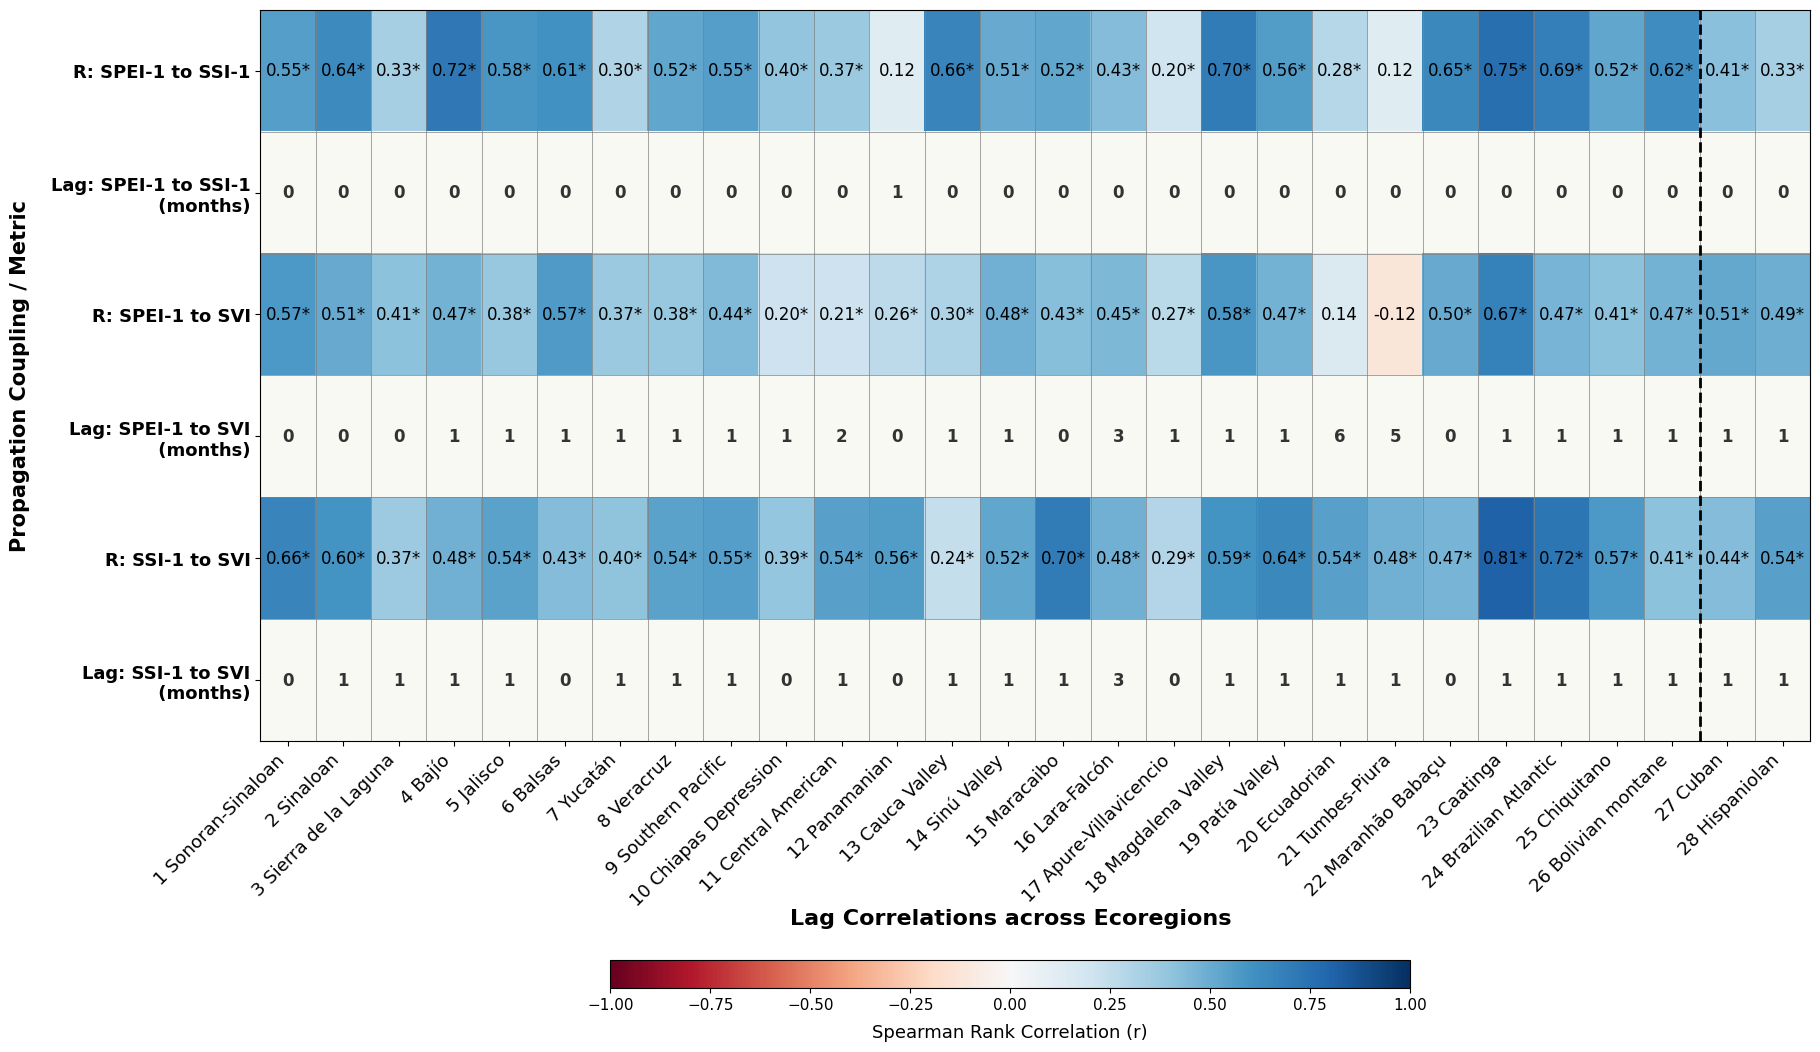

In [ ]:
if 'df_propagation_lags' in globals() and not df_propagation_lags.empty:
    df_plot = df_propagation_lags.copy()

    desired_order_local = ECOREGION_ORDER

    label_mapping_local = SHORT_LABELS

    present_order = [eco for eco in desired_order_local if eco in df_plot['ECO_NAME'].values]
    df_plot['ECO_NAME'] = pd.Categorical(df_plot['ECO_NAME'], categories=present_order, ordered=True)
    df_plot = df_plot.sort_values('ECO_NAME').reset_index(drop=True)

    rows_definition = [
        {'name': 'R: SPEI-1 to SSI-1', 'val_col': 'R_SPEI1_to_SSI1', 'sig_col': 'P_SPEI1_to_SSI1_sig', 'type': 'R'},
        {'name': 'Lag: SPEI-1 to SSI-1\n (months)', 'val_col': 'Lag_SPEI1_to_SSI1', 'type': 'Lag'},
        {'name': 'R: SPEI-1 to SVI', 'val_col': 'R_SPEI1_to_SVI', 'sig_col': 'P_SPEI1_to_SVI_sig', 'type': 'R'},
        {'name': 'Lag: SPEI-1 to SVI\n (months)', 'val_col': 'Lag_SPEI1_to_SVI', 'type': 'Lag'},
        {'name': 'R: SSI-1 to SVI', 'val_col': 'R_SSI1_to_SVI', 'sig_col': 'P_SSI1_to_SVI_sig', 'type': 'R'},
        {'name': 'Lag: SSI-1 to SVI\n (months)', 'val_col': 'Lag_SSI1_to_SVI', 'type': 'Lag'},
    ]

    num_rows = len(rows_definition)
    num_cols = len(df_plot)

    val_matrix = np.zeros((num_rows, num_cols))
    annot_matrix = []

    for r_idx, row_def in enumerate(rows_definition):
        row_annots = []
        for c_idx, eco_row in df_plot.iterrows():
            val = eco_row[row_def['val_col']]
            if pd.isna(val):
                val_matrix[r_idx, c_idx] = np.nan
                row_annots.append('N/A')
            else:
                val_matrix[r_idx, c_idx] = val
                if row_def['type'] == 'R':
                    sig = eco_row.get(row_def['sig_col'], False)
                    row_annots.append(f"{val:.2f}*" if sig else f"{val:.2f}")
                else:
                    row_annots.append(f"{int(val)}")
        annot_matrix.append(row_annots)

    annot_matrix = np.array(annot_matrix)

    cmap_r = matplotlib.colormaps['RdBu']
    norm_r = mcolors.Normalize(vmin=-1.0, vmax=1.0)

    rgba_matrix = np.ones((num_rows, num_cols, 4))

    for r_idx, row_def in enumerate(rows_definition):
        for c_idx in range(num_cols):
            val = val_matrix[r_idx, c_idx]
            if pd.isna(val):
                rgba_matrix[r_idx, c_idx] = [0.95, 0.95, 0.95, 1.0]
            elif row_def['type'] == 'R':
                rgba_matrix[r_idx, c_idx] = cmap_r(norm_r(val))
            else:

                rgba_matrix[r_idx, c_idx] = [0.98, 0.98, 0.96, 1.0]

    fig, ax = plt.subplots(figsize=(20, 9.5))

    ax.imshow(rgba_matrix, aspect='auto', interpolation='nearest')

    for r_idx in range(num_rows):
        is_lag = rows_definition[r_idx]['type'] == 'Lag'
        font_weight = 'bold' if is_lag else 'normal'
        font_color = '#333333' if is_lag else 'black'
        for c_idx in range(num_cols):
            ax.text(
                c_idx, r_idx, annot_matrix[r_idx, c_idx],
                va='center', ha='center',
                color=font_color,
                fontweight=font_weight,
                fontsize=12
            )

    ax.set_xticks(np.arange(num_cols))
    short_cols = [label_mapping_local.get(name, name) for name in df_plot['ECO_NAME']]
    ax.set_xticklabels(short_cols, rotation=45, ha='right', fontsize=13)

    ax.set_yticks(np.arange(num_rows))
    row_labels = [r['name'] for r in rows_definition]
    ax.set_yticklabels(row_labels, fontsize=13, fontweight='bold')

    ax.set_xticks(np.arange(num_cols + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(num_rows + 1) - 0.5, minor=True)
    ax.grid(which='minor', color='grey', linestyle='-', linewidth=0.5)
    ax.tick_params(which='minor', length=0)

    if LAST_CONTINENTAL in df_plot['ECO_NAME'].values:
        idx = df_plot[df_plot['ECO_NAME'] == LAST_CONTINENTAL].index[0]
        ax.axvline(x=idx + 0.5, color='black', linewidth=2, linestyle='--')

    cbar_ax = fig.add_axes([0.3, -0.15, 0.4, 0.03])
    sm = plt.cm.ScalarMappable(cmap='RdBu', norm=norm_r)
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Spearman Rank Correlation (r)', fontsize=13, labelpad=8)
    cbar.ax.tick_params(labelsize=11)

    ax.set_ylabel('Propagation Coupling / Metric', fontsize=15, fontweight='bold', labelpad=15)
    plt.title('Lag Correlations across Ecoregions',
              fontsize=16, fontweight='bold', pad=25)

    plt.savefig(out_path('drought_propagation_lags_matrix.png'), dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Error: df_propagation_lags is not defined or empty. Please ensure the propagation analysis has been run.")

### 6.4 Lag-correlation curves with block-bootstrap confidence intervals

Spearman correlation as a function of lag (0–6 months) for SPEI-1 vs SVI, SSI-1 vs SVI and SPEI-1 vs SSI-1, with 95% moving-block bootstrap bands (`N_BOOT_CURVES` resamples). FDR correction is applied across all ecoregions, pairs and lags together.

Calculating lag-correlations and block-bootstrap CIs for all relationships and lags...

✓ Full lag-correlation curves with CIs and FDR significance prepared.


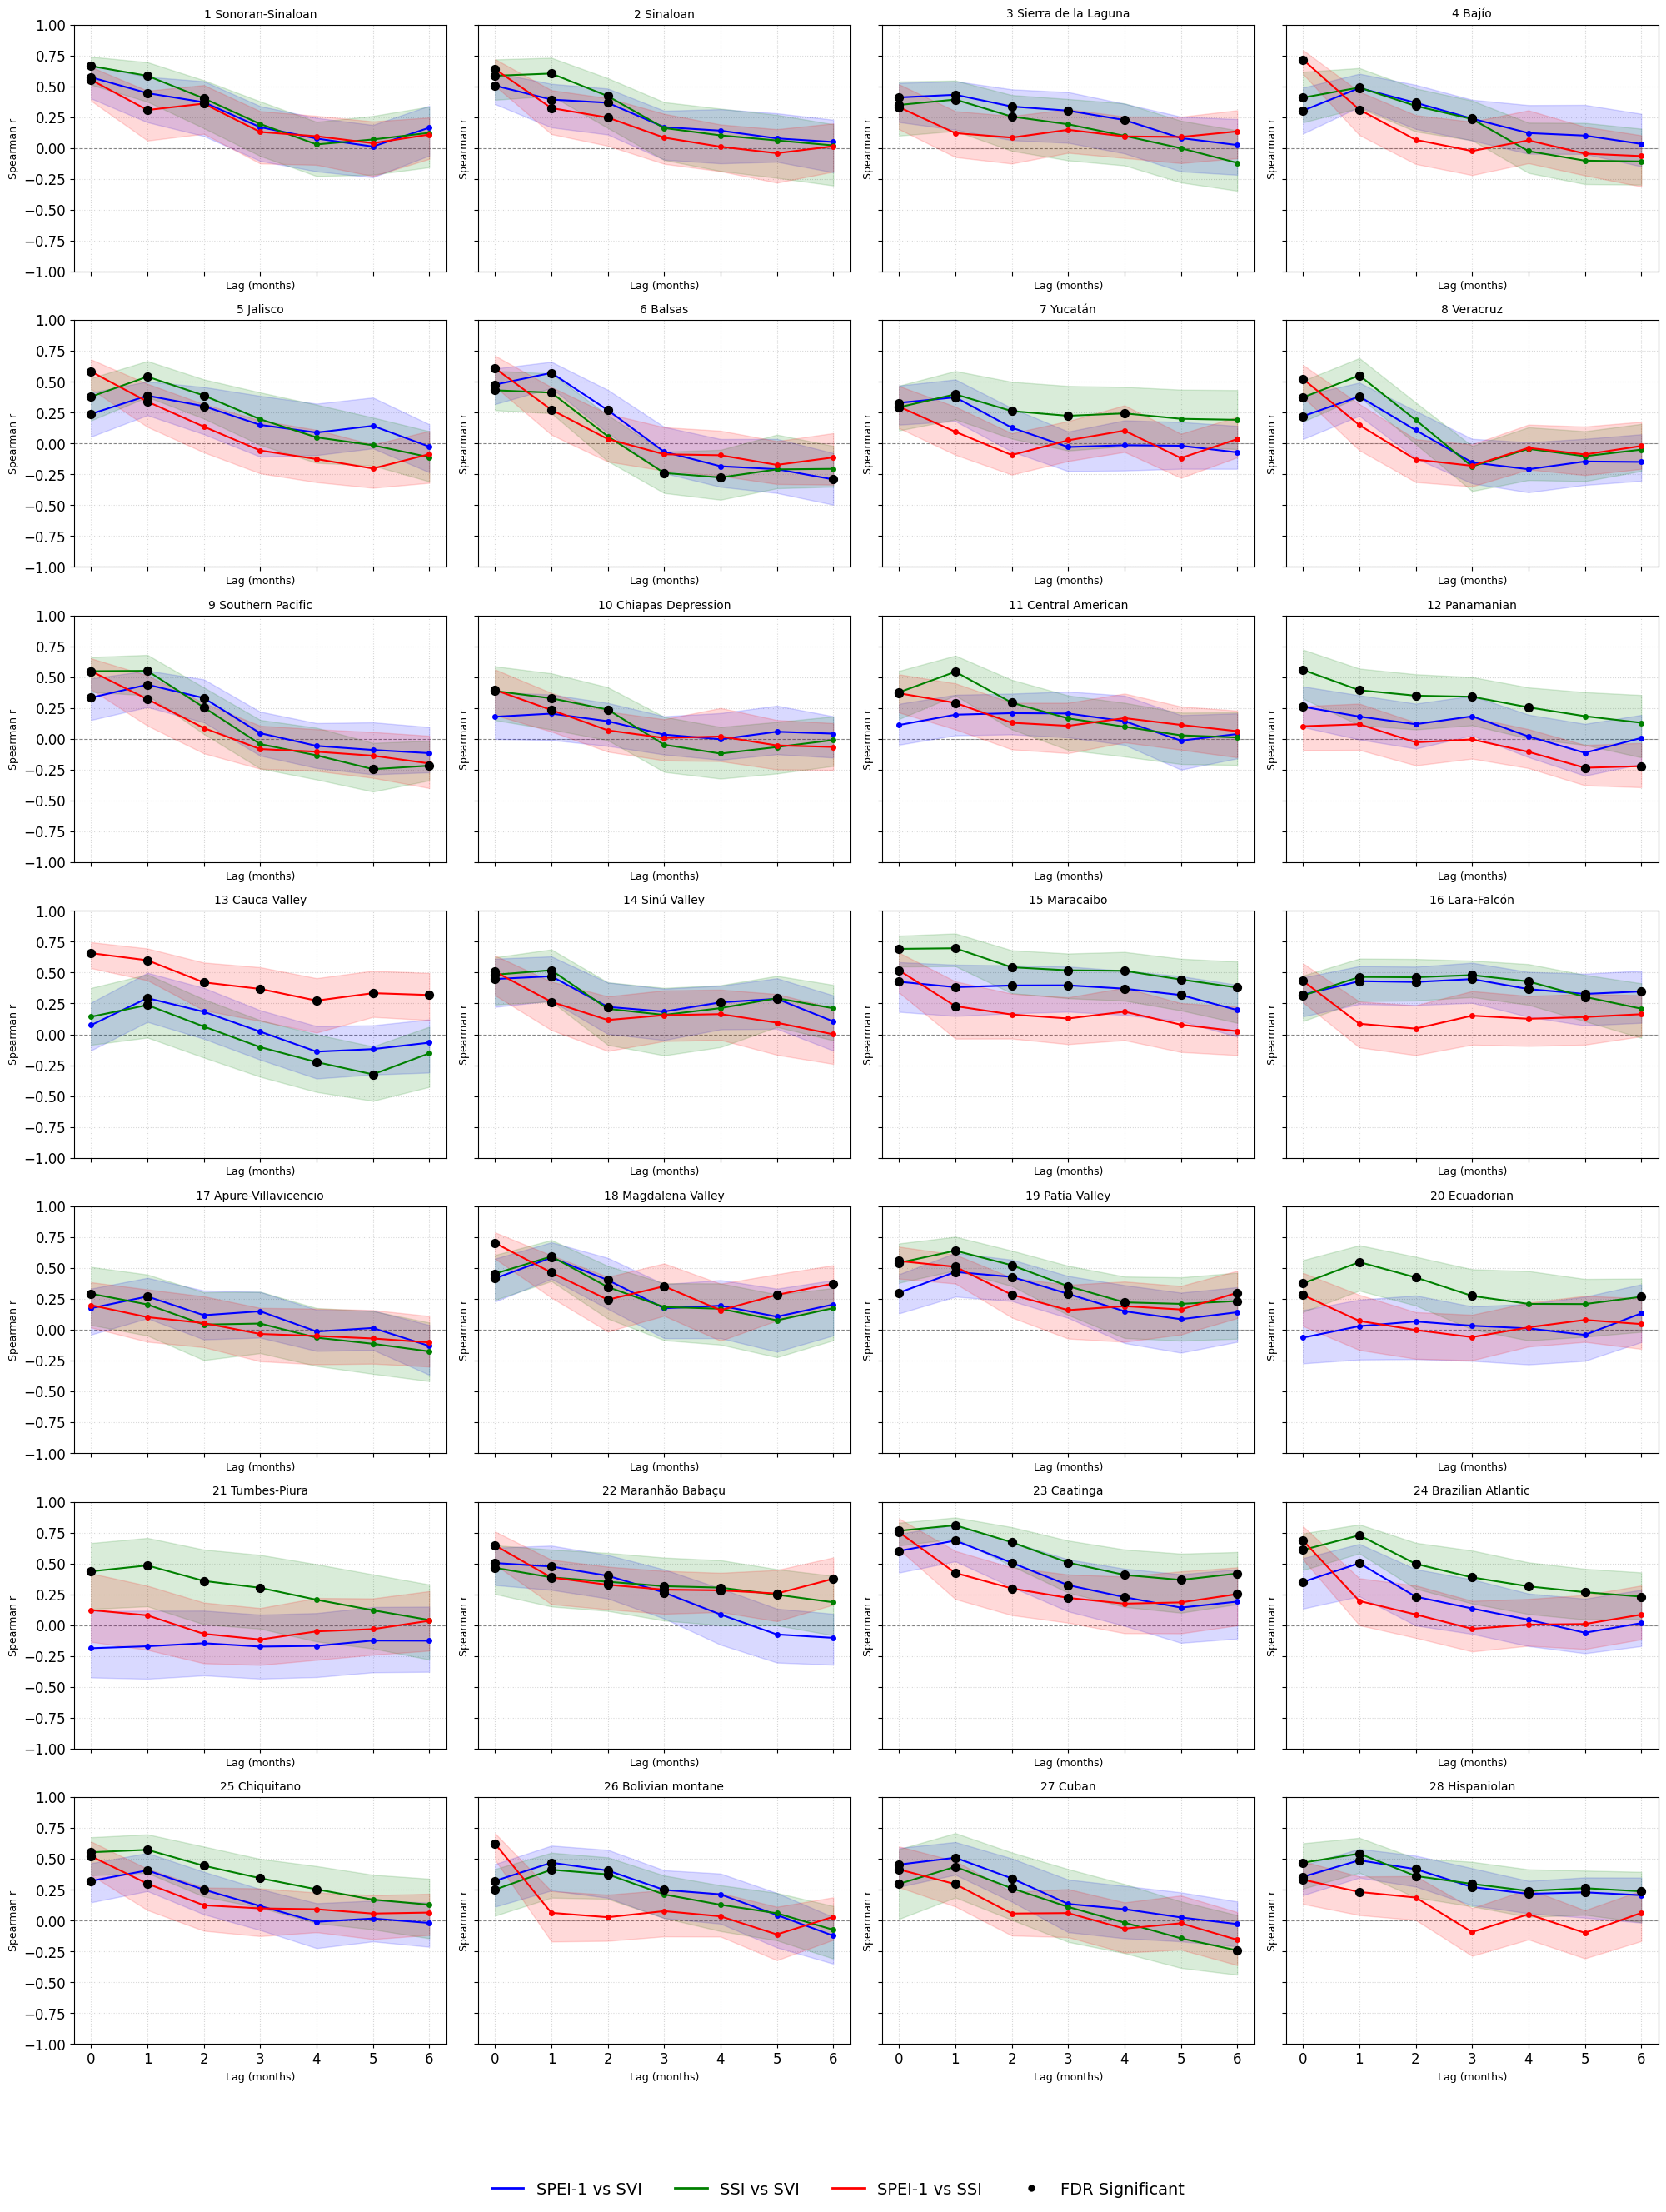

  -> saved outputs/lag_correlation_curves_ci.csv


In [ ]:
desired_feature_order = ECOREGION_ORDER
label_mapping = SHORT_LABELS

relationships = [
    {'predictor': 'spei_01', 'target': 'SVI_detrended', 'label': 'SVI vs SPEI-1'},
    {'predictor': 'SSI-1', 'target': 'SVI_detrended', 'label': 'SVI vs SSI-1'},
    {'predictor': 'spei_01', 'target': 'SSI-1', 'label': 'SPEI-1 vs SSI-1'}
]

max_lag = MAX_LAG
np.random.seed(RANDOM_SEED)

all_bootstrapped_results = []
all_p_values_for_fdr = []

unique_eco_names = [eco for eco in desired_feature_order if eco in df_all_indices['ECO_NAME'].unique()]

print("Calculating lag-correlations and block-bootstrap CIs for all relationships and lags...")

for eco_name in unique_eco_names:
    df_eco = df_all_indices[df_all_indices['ECO_NAME'] == eco_name].copy()

    max_len_for_bootstrap = len(df_eco[['spei_01', 'SSI-1', 'SVI_detrended']].dropna())
    if max_len_for_bootstrap > 0:
        block_size_for_eco = max(2, int(max_len_for_bootstrap**(1/3)))
    else:
        block_size_for_eco = 5

    for rel in relationships:
        predictor = rel['predictor']
        target = rel['target']
        comp_label = rel['label']

        for lag in range(0, max_lag + 1):
            x_orig_data = df_eco[predictor].iloc[:-lag].values if lag > 0 else df_eco[predictor].values
            y_orig_data = df_eco[target].iloc[lag:].values if lag > 0 else df_eco[target].values

            temp_df_orig_corr = pd.DataFrame({'x': x_orig_data, 'y': y_orig_data}).dropna()

            r_orig, p_orig = (np.nan, np.nan)
            if len(temp_df_orig_corr) >= 10 and len(np.unique(temp_df_orig_corr['x'])) > 1 and len(np.unique(temp_df_orig_corr['y'])) > 1:
                r_orig, p_orig = spearmanr(temp_df_orig_corr['x'], temp_df_orig_corr['y'])

            ci_low, ci_high = np.nan, np.nan
            if not np.isnan(r_orig):
                boot_corrs = block_bootstrap_correlation(
                    df_eco, predictor, target, lag, block_size_override=block_size_for_eco,
                    n_bootstraps=N_BOOT_CURVES
                )
                if len(boot_corrs) >= 20:
                    ci_low = np.percentile(boot_corrs, 2.5)
                    ci_high = np.percentile(boot_corrs, 97.5)

            all_bootstrapped_results.append({
                'ECO_NAME': eco_name,
                'Comparison_Type': comp_label,
                'Lag_months': lag,
                'Spearman_r': r_orig,
                'p_value': p_orig,
                'CI_low': ci_low,
                'CI_high': ci_high
            })
            if not np.isnan(p_orig):
                all_p_values_for_fdr.append(p_orig)
df_full_curves_ci = pd.DataFrame(all_bootstrapped_results)

if all_p_values_for_fdr:
    _, p_adj_fdr, _, _ = multipletests(all_p_values_for_fdr, alpha=0.05, method='fdr_bh')

    p_value_index = 0
    for idx, row in df_full_curves_ci.iterrows():
        if not np.isnan(row['p_value']):
            df_full_curves_ci.loc[idx, 'p_fdr'] = p_adj_fdr[p_value_index]
            p_value_index += 1
        else:
            df_full_curves_ci.loc[idx, 'p_fdr'] = np.nan
else:
    df_full_curves_ci['p_fdr'] = np.nan

df_full_curves_ci['is_significant_fdr'] = df_full_curves_ci['p_fdr'] < 0.05

print("\n✓ Full lag-correlation curves with CIs and FDR significance prepared.")

# --- Plotting ---
num_ecoregions = len(unique_eco_names)
num_cols = 4
num_rows = (num_ecoregions + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 4), sharex=True, sharey=True)
axes = axes.flatten()

comparison_colors = {
    'SVI vs SPEI-1': 'blue',
    'SVI vs SSI-1': 'green',
    'SPEI-1 vs SSI-1': 'red'
}

legend_elements = [
    plt.Line2D([0], [0], color='blue', lw=2, label='SPEI-1 vs SVI'),
    plt.Line2D([0], [0], color='green', lw=2, label='SSI vs SVI'),
    plt.Line2D([0], [0], color='red', lw=2, label='SPEI-1 vs SSI'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=7, label='FDR Significant')
]

for i, eco_name in enumerate(unique_eco_names):
    ax = axes[i]
    eco_data = df_full_curves_ci[df_full_curves_ci['ECO_NAME'] == eco_name].copy()

    short_name = label_mapping.get(eco_name, eco_name)

    if eco_data.empty or eco_data['Spearman_r'].dropna().empty:
        ax.set_title(f'{short_name}\n(No Data)', fontsize=10)
        ax.set_xlabel('Lag (months)', fontsize=10)
        ax.set_ylabel('Spearman r', fontsize=10)
        ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
        ax.set_ylim(-1, 1)
        ax.set_xticks(range(max_lag + 1))
        continue

    for rel in relationships:
        comp_label = rel['label']
        color = comparison_colors[comp_label]
        comp_data = eco_data[eco_data['Comparison_Type'] == comp_label].sort_values('Lag_months')

        if not comp_data.empty and not comp_data['Spearman_r'].dropna().empty:
            ax.plot(comp_data['Lag_months'], comp_data['Spearman_r'], marker='o', color=color, linewidth=1.5, markersize=4, zorder=3)

            ax.fill_between(
                comp_data['Lag_months'],
                comp_data['CI_low'],
                comp_data['CI_high'],
                color=color,
                alpha=0.15,
                label=f'{comp_label} 95% CI',
                zorder=2
            )

            significant_points = comp_data[comp_data['is_significant_fdr']]
            if not significant_points.empty:
                ax.scatter(
                    significant_points['Lag_months'],
                    significant_points['Spearman_r'],
                    color='black',
                    s=50,
                    zorder=4
                )

    ax.set_title(f'{short_name}', fontsize=10)
    ax.set_xlabel('Lag (months)', fontsize=9)
    ax.set_ylabel('Spearman r', fontsize=9)
    ax.set_xticks(range(max_lag + 1))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.set_ylim(-1, 1)
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8, zorder=1)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, 0), ncol=4, fontsize=14, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig(out_path('lag_correlation_curves_ci.png'), dpi=300, bbox_inches='tight')
plt.show()